<h1 style='font-weight:bold; color:#003366; text-align:center;'>Proyecto Final B: Arroyo Capital</h1>

<h3 style='font-weight:bold; color:#003366; text-align:center;'>Tesis de inversión y portafolio en la industria del cine</h3>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Programación Analítica II · Universidad de Montevideo · S2 2026</h4>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Docente Camila Palomeque</h4>

## Objetivo y cómo se lee este notebook

Arroyo Capital va a colocar **USD 500 millones** en producción cinematográfica durante tres años y nadie
en el fondo invirtió nunca en cine. El Chief Investment Officer no pide adivinar qué película va a funcionar:
pide saber **qué clase de película tiene mejor relación entre riesgo y retorno**, y **cuánto se puede perder**.

El notebook sigue las cinco etapas de la letra y corre de arriba abajo sin intervención:

1. Auditoría y limpieza de datos (cada cambio queda registrado en una bitácora con el porcentaje de la base afectado).
2. Creación de variables (dólares constantes, retorno y regla del 2,5×).
3. Análisis de negocio (crecimiento, retorno por segmento, riesgo).
4. Visualizaciones (incluye un gráfico interactivo con Plotly).
5. Tesis de inversión (arquetipos, asignación de los USD 500 M, simulación y prueba fuera de muestra).

**Convenciones.** Los montos están en USD. *Corrientes* = del año de estreno; *constantes* = dólares de 2020.
El **retorno** (o ROI en esta letra) es la recaudación mundial dividida por el presupuesto de producción,
es decir un múltiplo: 2,5 significa que la película recaudó 2,5 veces lo que costó. Una película
**recupera** la inversión si ese múltiplo es de 2,5 o más (regla de la industria).

<h2 style='font-weight:bold; color:#003366;'>0. Configuración</h2>

In [1]:
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from IPython.display import display
from scipy import stats

# ---- Constantes del análisis (cada una con su razón) ----
SEMILLA = 42  # reproducibilidad de las simulaciones
ANIO_BASE = 2020  # año cuyos dólares usamos como "constantes"
UMBRAL_RECUPERO = 2.5  # regla de la industria: recaudación >= 2,5 x presupuesto
# Umbral estricto: el exhibidor se queda con 50% de la boletería y el marketing
# cuesta ~75% del presupuesto (punto medio de 50%-100%). Para que el estudio
# recupere todo: 0,5 x recaudación = 1,75 x presupuesto, o sea 3,5 x.
PARTE_ESTUDIO = 0.5  # fracción de la boletería que no se queda el exhibidor
MARKETING_SOBRE_PRESUPUESTO = 0.75
UMBRAL_ESTRICTO = (1 + MARKETING_SOBRE_PRESUPUESTO) / PARTE_ESTUDIO  # = 3,5
ANIO_CORTE = 2014  # criterios con películas hasta 2014, prueba 2015-2020
MIN_PELICULAS = 30  # un segmento con menos películas no se interpreta
PRESUPUESTO_FONDO = 500e6  # USD 500 millones a colocar
N_SIMULACIONES = 20_000

rng = np.random.default_rng(SEMILLA)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")


def ruta_datos(nombre_archivo):
    """Busca el archivo en las ubicaciones habituales del repo (y de Colab)."""
    candidatas = [
        Path("../datos") / nombre_archivo,
        Path("datos") / nombre_archivo,
        Path("/content/datos") / nombre_archivo,
        Path(nombre_archivo),
    ]
    for candidata in candidatas:
        if candidata.exists():
            return candidata
    raise FileNotFoundError(f"No encuentro {nombre_archivo}. Revisá la carpeta datos/.")


CARPETA_SALIDAS = ruta_datos("peliculas.csv").parent.parent / "salidas"
CARPETA_SALIDAS.mkdir(exist_ok=True)


def guardar_figura(figura, nombre):
    """Guarda la figura en salidas/ para poder usarla en la presentación."""
    figura.savefig(CARPETA_SALIDAS / f"{nombre}.png", dpi=150, bbox_inches="tight")

<h2 style='font-weight:bold; color:#003366;'>Etapa 1: Análisis exploratorio y correcciones de calidad</h2>

<h3 style='font-weight:bold; color:#0033BB;'>1.1 Carga de los archivos</h3>

Los tipos se declaran al cargar. Una excepción deliberada: `fecha_estreno` entra como **texto**, porque
la columna mezcla dos formatos (`2010-07-01` y `16/11/1988`) y `parse_dates` no puede resolver los dos a la vez.
Se parsea después, con una función que prueba cada formato.

In [2]:
TIPOS_PELICULAS = {
    "id_pelicula": "int64",
    "titulo": "string",
    "anio_estreno": "int64",
    "fecha_estreno": "string",
    "genero": "string",
    "clasificacion": "string",
    "pais_origen": "string",
    "es_secuela": "string",
    "director": "string",
    "guionista": "string",
    "protagonista": "string",
    "productora": "string",
    "duracion_minutos": "float64",
    "puntaje_imdb": "float64",
    "cantidad_votos": "float64",
    "presupuesto_usd": "float64",
    "recaudacion_mundial_usd": "float64",
}

peliculas_crudo = pd.read_csv(ruta_datos("peliculas.csv"), dtype=TIPOS_PELICULAS)
ipc = pd.read_csv(ruta_datos("ipc_eeuu.csv"), dtype={"anio": "int64", "ipc_eeuu": "float64"})

BASE_INICIAL = len(peliculas_crudo)  # denominador de todos los porcentajes de la bitácora

# Verificación de la carga: tamaño, primeras filas y el índice de precios completo
print("peliculas.csv:", peliculas_crudo.shape, "| ipc_eeuu.csv:", ipc.shape)
assert ipc["ipc_eeuu"].notna().all(), "El IPC tiene faltantes"
assert set(range(1980, 2021)) == set(ipc["anio"]), "El IPC no cubre 1980-2020"
display(peliculas_crudo.head(5))
display(ipc.head(3))

peliculas.csv: (7740, 17) | ipc_eeuu.csv: (41, 2)


,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.00,5.50,"13,000.00","800,000.00","156,190.00"
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.00,3.20,"5,000.00","17,000,000.00","2,315,683.00"
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.00,6.20,"44,000.00","65,000,000.00","69,474,661.00"
3,13042,Celtic Pride,1996,1996-04-19,Comedia,Mayores de 13,Estados Unidos,No,Tom DeCerchio,Judd Apatow,Damon Wayans,Caravan Pictures,91.00,5.30,"9,600.00",NaN,"9,255,027.00"
4,11961,Kafka,1991,1991-11-15,Drama,Mayores de 13,Francia,No,Steven Soderbergh,Lem Dobbs,Jeremy Irons,Baltimore Pictures,98.00,6.90,"9,600.00","11,000,000.00","1,059,071.00"


,anio,ipc_eeuu
0,1980,82.40
1,1981,90.90
2,1982,96.50


<h3 style='font-weight:bold; color:#0033BB;'>1.2 Estructura de la base</h3>

In [3]:
print(f"Filas: {peliculas_crudo.shape[0]:,} | Columnas: {peliculas_crudo.shape[1]}")
print("\nTipos de dato")
print(peliculas_crudo.dtypes.to_string())

print("\nCantidad de categorías (valores distintos) en las variables de texto")
columnas_texto = peliculas_crudo.select_dtypes(exclude="number").columns
print(peliculas_crudo[columnas_texto].nunique().sort_values(ascending=False).to_string())

print("\nDescripción estadística de las variables continuas")
columnas_numericas = [
    "duracion_minutos",
    "puntaje_imdb",
    "cantidad_votos",
    "presupuesto_usd",
    "recaudacion_mundial_usd",
]
display(peliculas_crudo[columnas_numericas].describe().round(2))

Filas: 7,740 | Columnas: 17

Tipos de dato
id_pelicula                  int64
titulo                      string
anio_estreno                 int64
fecha_estreno               string
genero                      string
clasificacion               string
pais_origen                 string
es_secuela                  string
director                    string
guionista                   string
protagonista                string
productora                  string
duracion_minutos           float64
puntaje_imdb               float64
cantidad_votos             float64
presupuesto_usd            float64
recaudacion_mundial_usd    float64

Cantidad de categorías (valores distintos) en las variables de texto
titulo           7512
guionista        4535
fecha_estreno    3712
director         2949
protagonista     2814
productora       2744
pais_origen        64
genero             25
clasificacion      10
es_secuela          2

Descripción estadística de las variables continuas


,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd
count,"7,736.00","7,737.00","7,737.00","5,551.00","7,549.00"
mean,108.83,6.37,"88,122.35","35,000,792.40","78,600,686.19"
std,44.86,1.03,"163,333.63","41,215,579.81","168,497,298.56"
min,0.00,0.00,7.00,-1.00,"-622,674,139.00"
25%,95.00,5.80,"9,100.00","10,000,000.00","4,515,258.00"
50%,104.00,6.50,"33,000.00","20,000,000.00","20,240,502.00"
75%,116.00,7.10,"93,000.00","43,000,000.00","76,019,048.00"
max,999.00,9.30,"2,400,000.00","356,000,000.00","2,847,246,203.00"


**Lectura.** La base tiene 7.740 filas y 17 columnas, una por película. Ya en el `describe` se ve que algo está mal:
el presupuesto mínimo es **-1** dólar, la recaudación mínima es **-622 millones**, hay películas de **0** y de **999** minutos y puntajes de IMDb de **0** en una escala de 1 a 10.
Las variables de texto también tienen más categorías de las que corresponden: 25 géneros escritos (en realidad son 18), 10 grafías de clasificación (el catálogo oficial tiene 6) y 64 países.
Todo eso se audita y se corrige en las secciones siguientes.

<h3 style='font-weight:bold; color:#0033BB;'>1.3 Duplicados: filas repetidas y películas repetidas</h3>

Son dos problemas distintos y se resuelven distinto:

- **Fila exactamente duplicada**: las 17 columnas coinciden. Es una carga doble y se borra sin discusión.
- **Película repetida con datos distintos**: mismo título y año, pero algún dato cambia. Hay que decidir cuál de las dos filas es la verdadera.

In [4]:
duplicadas_exactas = peliculas_crudo.duplicated().sum()
ids_repetidos = peliculas_crudo.duplicated(subset="id_pelicula").sum()
print(
    f"Filas exactamente duplicadas: {duplicadas_exactas} ({duplicadas_exactas / BASE_INICIAL:.2%} de la base)"
)
print(f"Identificadores repetidos   : {ids_repetidos}")

# Sacamos las exactas y miramos si quedan películas repetidas con datos distintos
sin_exactas = peliculas_crudo.drop_duplicates().copy()
clave_pelicula = ["titulo", "anio_estreno"]
repetidas = sin_exactas[sin_exactas.duplicated(clave_pelicula, keep=False)].sort_values(
    clave_pelicula + ["id_pelicula"]
)
print(
    f"\nPelículas con título y año repetidos tras quitar las exactas: {len(repetidas)} filas, "
    f"{repetidas[clave_pelicula].drop_duplicates().shape[0]} películas"
)

# ¿Qué columnas cambian dentro de cada par?
columnas_que_cambian = (
    repetidas.groupby(clave_pelicula).nunique(dropna=False).gt(1).sum().loc[lambda serie: serie > 0]
)
print("\nColumnas que cambian dentro de los pares (cantidad de pares donde difieren):")
print(columnas_que_cambian.to_string())
display(
    repetidas[
        ["id_pelicula", "titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"]
    ].head(8)
)

Filas exactamente duplicadas: 58 (0.75% de la base)
Identificadores repetidos   : 58

Películas con título y año repetidos tras quitar las exactas: 28 filas, 14 películas

Columnas que cambian dentro de los pares (cantidad de pares donde difieren):
id_pelicula        14
presupuesto_usd    14


,id_pelicula,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
1970,12898,Bio-Dome,1996,"15,000,000.00","13,427,615.00"
2653,90001,Bio-Dome,1996,"19,697,118.00","13,427,615.00"
2212,13101,Breakdown,1997,"36,000,000.00","50,159,144.00"
1747,90004,Breakdown,1997,"31,901,667.00","50,159,144.00"
5906,16378,Cloudy with a Chance of Meatballs 2,2013,"78,000,000.00","274,325,949.00"
3074,90008,Cloudy with a Chance of Meatballs 2,2013,"93,580,153.00","274,325,949.00"
6101,13883,Enemy at the Gates,2001,"68,000,000.00","96,976,270.00"
5510,90011,Enemy at the Gates,2001,"43,107,007.00","96,976,270.00"


Los pares difieren solo en el **identificador** (los repetidos tienen id 9000x, fuera del rango 10001-17xxx del resto de la base)
y en el **presupuesto**. Para decidir cuál presupuesto es el verdadero se mira si es un número "redondo", que es como
están cargados casi todos los presupuestos de la base (15.000.000, 20.000.000...).

In [5]:
def proporcion_redondos(serie, paso=100_000):
    """Proporción de valores que son múltiplos exactos de `paso` (ej.: 15.000.000)."""
    serie = serie.dropna()
    return (serie % paso == 0).mean()


originales = repetidas[repetidas["id_pelicula"] < 90_000]
copias = repetidas[repetidas["id_pelicula"] >= 90_000]
print(
    f"Presupuestos redondos en toda la base : {proporcion_redondos(sin_exactas['presupuesto_usd']):.0%}"
)
print(
    f"Presupuestos redondos en los originales: {proporcion_redondos(originales['presupuesto_usd']):.0%}"
)
print(
    f"Presupuestos redondos en las copias    : {proporcion_redondos(copias['presupuesto_usd']):.0%}"
)

Presupuestos redondos en toda la base : 96%
Presupuestos redondos en los originales: 100%
Presupuestos redondos en las copias    : 0%


**Decisión.** Las 58 filas exactamente duplicadas (0,75% de la base) son una carga doble y se borran.
Las 14 películas repetidas con datos distintos son otro problema: solo difieren en el identificador y en el presupuesto.
Los originales tienen un presupuesto redondo en el 100% de los casos, igual que el 96% de la base; las copias, en el 0%.
Eso indica que las copias son registros agregados con un presupuesto alterado, así que se conserva el original (id menor).
El efecto sobre el retorno es mínimo (el retorno medio pasa de 26,46x a 26,70x y la mediana se mantiene en 1,86x), pero si no se encuentran, estas filas duplican películas en cada agrupamiento.

In [6]:
bitacora = []  # una fila por cada vez que se borra, imputa o modifica algo


def registrar(paso, afectadas, decision):
    """Agrega una línea a la bitácora con el % de la base inicial afectado."""
    bitacora.append(
        {
            "paso": paso,
            "filas_afectadas": int(afectadas),
            "pct_base_inicial": afectadas / BASE_INICIAL * 100,
            "decision": decision,
        }
    )


def estado_retorno(df, etapa):
    """Foto del retorno (recaudación / presupuesto) para ver si una corrección mueve las conclusiones."""
    valido = (df["presupuesto_usd"] > 0) & df["recaudacion_mundial_usd"].notna()
    roi = df.loc[valido, "recaudacion_mundial_usd"] / df.loc[valido, "presupuesto_usd"]
    return {
        "etapa": etapa,
        "filas": len(df),
        "con_retorno_calculable": int(valido.sum()),
        "retorno_medio": roi.mean(),
        "retorno_mediano": roi.median(),
        "pct_recupera": (roi >= UMBRAL_RECUPERO).mean() * 100,
    }


fotos = [estado_retorno(peliculas_crudo, "0. Base cruda")]

# Decisión 1: borrar las filas exactamente duplicadas
peliculas = peliculas_crudo.drop_duplicates().copy()
registrar(
    "Filas exactamente duplicadas", duplicadas_exactas, "Se borran: carga doble del mismo registro"
)
fotos.append(estado_retorno(peliculas, "1. Sin duplicados exactos"))

# Decisión 2: en las películas repetidas con datos distintos, nos quedamos con el id original (menor)
antes = len(peliculas)
peliculas = (
    peliculas.sort_values("id_pelicula").drop_duplicates(clave_pelicula, keep="first").copy()
)
registrar(
    "Películas repetidas con presupuesto distinto",
    antes - len(peliculas),
    "Se conserva el id original (<90000), cuyo presupuesto es redondo como el resto de la base",
)
fotos.append(estado_retorno(peliculas, "2. Sin películas repetidas"))
print(f"Filas: {BASE_INICIAL:,} -> {len(peliculas):,}")

Filas: 7,740 -> 7,668


<h3 style='font-weight:bold; color:#0033BB;'>1.4 Faltantes por columna</h3>

In [7]:
faltantes = pd.DataFrame(
    {
        "faltantes": peliculas.isna().sum(),
        "pct_faltante": peliculas.isna().mean() * 100,
    }
).loc[lambda tabla: tabla["faltantes"] > 0]
display(faltantes.sort_values("faltantes", ascending=False))

print("Algunas filas sin presupuesto:")
display(
    peliculas.loc[
        peliculas["presupuesto_usd"].isna(),
        ["titulo", "anio_estreno", "pais_origen", "genero", "recaudacion_mundial_usd"],
    ].head(6)
)
print("Algunas filas sin recaudación:")
display(
    peliculas.loc[
        peliculas["recaudacion_mundial_usd"].isna(),
        ["titulo", "anio_estreno", "pais_origen", "presupuesto_usd"],
    ].head(6)
)

,faltantes,pct_faltante
presupuesto_usd,2171,28.31
recaudacion_mundial_usd,189,2.46
clasificacion,77,1.00
productora,15,0.20
duracion_minutos,4,0.05
pais_origen,3,0.04
cantidad_votos,3,0.04
guionista,3,0.04
puntaje_imdb,3,0.04
protagonista,1,0.01


Algunas filas sin presupuesto:


,titulo,anio_estreno,pais_origen,genero,recaudacion_mundial_usd
1622,Fame,1980,Estados Unidos,Drama,"21,202,829.00"
2987,Stir Crazy,1980,Estados Unidos,Comedia,"101,300,000.00"
5363,Urban Cowboy,1980,Estados Unidos,Drama,"46,918,287.00"
5591,Altered States,1980,Estados Unidos,Terror,"19,853,892.00"
870,Little Darlings,1980,Estados Unidos,Comedia,"34,326,249.00"
1125,My Bodyguard,1980,Estados Unidos,Comedia,"22,482,952.00"


Algunas filas sin recaudación:


,titulo,anio_estreno,pais_origen,presupuesto_usd
1450,Raise the Titanic,1980,Reino Unido,"36,000,000.00"
2577,Breaker Morant,1980,Australia,NaN
7556,The Boogey Man,1980,Estados Unidos,"300,000.00"
6325,Lion of the Desert,1980,Libya,"35,000,000.00"
6134,Can't Stop the Music,1980,EE.UU.,"20,000,000.00"
6102,The Private Eyes,1980,Estados Unidos,NaN


Estos son los faltantes **declarados** (celdas vacías). Más abajo aparecen faltantes **disfrazados de dato**
(ceros, -1, 999) que el `isna()` no ve, y por eso la cifra final de películas sin presupuesto va a ser mayor.

<h3 style='font-weight:bold; color:#0033BB;'>1.5 Valores que no deberían poder existir</h3>

In [8]:
rarezas = {
    "duracion = 0 minutos": peliculas["duracion_minutos"] == 0,
    "duracion = 999 minutos": peliculas["duracion_minutos"] == 999,
    "puntaje IMDb = 0 (escala 1 a 10)": peliculas["puntaje_imdb"] == 0,
    "puntaje IMDb > 10": peliculas["puntaje_imdb"] > 10,
    "presupuesto = 0": peliculas["presupuesto_usd"] == 0,
    "presupuesto = -1": peliculas["presupuesto_usd"] == -1,
    "presupuesto < 0 (otro valor)": peliculas["presupuesto_usd"] < -1,
    "recaudacion negativa": peliculas["recaudacion_mundial_usd"] < 0,
    "recaudacion = 0": peliculas["recaudacion_mundial_usd"] == 0,
    "votos <= 0": peliculas["cantidad_votos"] <= 0,
}
tabla_rarezas = pd.Series({nombre: int(mascara.sum()) for nombre, mascara in rarezas.items()})
display(
    tabla_rarezas.to_frame("filas").assign(pct_base=lambda t: t["filas"] / len(peliculas) * 100)
)

# Duraciones largas: ¿son errores o son películas largas de verdad?
print("\nDuraciones entre 300 y 998 minutos:")
display(
    peliculas.loc[
        peliculas["duracion_minutos"].between(300, 998),
        ["titulo", "anio_estreno", "duracion_minutos"],
    ]
)
print("Recaudaciones negativas:")
display(
    peliculas.loc[
        peliculas["recaudacion_mundial_usd"] < 0,
        ["titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"],
    ].head(6)
)

,filas,pct_base
duracion = 0 minutos,18,0.23
duracion = 999 minutos,16,0.21
puntaje IMDb = 0 (escala 1 a 10),22,0.29
puntaje IMDb > 10,0,0.00
presupuesto = 0,26,0.34
presupuesto = -1,22,0.29
presupuesto < 0 (otro valor),0,0.00
recaudacion negativa,11,0.14
recaudacion = 0,0,0.00
votos <= 0,0,0.00



Duraciones entre 300 y 998 minutos:


,titulo,anio_estreno,duracion_minutos
6523,Little Dorrit,1987,357.00
6766,The Best of Youth,2003,366.00


Recaudaciones negativas:


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd
4241,Seems Like Old Times,1980,NaN,"-43,995,918.00"
7167,Critters,1986,"2,000,000.00","-13,167,232.00"
2646,"Planes, Trains & Automobiles",1987,"30,000,000.00","-49,530,280.00"
5055,Slam Dance,1987,"4,500,000.00","-406,881.00"
7679,Big Business,1988,NaN,"-40,150,487.00"
3932,The Long Day Closes,1992,NaN,"-22,765.00"


Qué se decide para cada caso, con su razón:

- **Duración 0 o 999, puntaje 0, presupuesto 0 o -1**: son *centinelas de faltante*, valores que alguien puso para decir "no sé". Una película de 0 minutos no existe, el IMDb no tiene puntaje 0 con cientos de miles de votos y un presupuesto de -1 dólar es imposible. Se pasan a `NaN`. Las duraciones de 357 y 366 minutos **no** se tocan: son películas reales muy largas (*Little Dorrit* y *The Best of Youth*).
- **Recaudación negativa**: no es faltante sino **signo invertido**. Los montos tienen magnitud de película real (*Ant-Man and the Wasp*: -622 M, y su presupuesto es de 162 M). Se pasa a valor absoluto. Abajo se verifica que con ese arreglo el retorno de esas filas cae en un rango normal.

In [9]:
# Verificación del arreglo de signo: ¿el retorno de las filas corregidas se ve como el del resto?
negativas = peliculas["recaudacion_mundial_usd"] < 0
retorno_corregido = (
    peliculas.loc[negativas, "recaudacion_mundial_usd"].abs()
    / peliculas.loc[negativas, "presupuesto_usd"]
)
retorno_resto = (
    peliculas.loc[~negativas, "recaudacion_mundial_usd"]
    / peliculas.loc[~negativas, "presupuesto_usd"]
)
print(f"Retorno mediano de las filas con signo corregido: {retorno_corregido.median():.2f}x")
print(f"Retorno mediano del resto de la base            : {retorno_resto.median():.2f}x")

# Aplicamos las decisiones
sentinelas = {
    "duracion_minutos": [0, 999],
    "puntaje_imdb": [0],
    "presupuesto_usd": [0, -1],
}
for columna, valores in sentinelas.items():
    mascara = peliculas[columna].isin(valores)
    registrar(
        f"Centinela en {columna} ({valores})",
        mascara.sum(),
        "Se reemplaza por NaN: es un 'no sé', no un dato",
    )
    peliculas.loc[mascara, columna] = np.nan

registrar(
    "Recaudación con signo negativo",
    negativas.sum(),
    "Se pasa a valor absoluto: magnitud coherente con una película real",
)
peliculas["recaudacion_mundial_usd"] = peliculas["recaudacion_mundial_usd"].abs()
fotos.append(estado_retorno(peliculas, "3. Sin centinelas ni signos"))

Retorno mediano de las filas con signo corregido: 1.34x
Retorno mediano del resto de la base            : 1.87x


<h3 style='font-weight:bold; color:#0033BB;'>1.6 Presupuestos cargados en otra escala</h3>

Un presupuesto de USD 6.000 para *Platoon* parece un error, pero hay películas que de verdad costaron poco,
así que mirar la columna sola no alcanza. La columna con la que hay que **cruzarlo es la recaudación**:

- una película de USD 6.000 que recauda 138 millones de dólares tendría un retorno de 23.000 veces. Eso no pasa en una película de estudio, pero sí pasa si el presupuesto está cargado **en miles de dólares** (USD 6 millones reales);
- una película genuinamente barata (*Clerks*, *Primer*) recauda poco en términos absolutos.

La regla operativa: presupuesto menor a USD 1 millón **y** retorno mayor a 100 veces. Se prueba qué tan sensible es el corte.

In [10]:
retorno_provisorio = peliculas["recaudacion_mundial_usd"] / peliculas["presupuesto_usd"]
presupuesto_bajo = peliculas["presupuesto_usd"] < 1_000_000

print("Sensibilidad del corte (presupuesto < USD 1 M y retorno mayor a X):")
for corte in [30, 50, 100, 200, 500, 1000]:
    print(
        f"  retorno > {corte:>4}x : {(presupuesto_bajo & (retorno_provisorio > corte)).sum():>3} películas"
    )

ROI_SOSPECHOSO = 100
sospechosas = presupuesto_bajo & (retorno_provisorio > ROI_SOSPECHOSO)

# Comparación: sospechosas contra películas realmente baratas (presupuesto bajo y retorno normal)
baratas_genuinas = presupuesto_bajo & ~sospechosas & peliculas["recaudacion_mundial_usd"].notna()
comparacion = pd.DataFrame(
    {
        "n": [sospechosas.sum(), baratas_genuinas.sum()],
        "recaudacion_mediana_usd": [
            peliculas.loc[sospechosas, "recaudacion_mundial_usd"].median(),
            peliculas.loc[baratas_genuinas, "recaudacion_mundial_usd"].median(),
        ],
        "votos_medianos": [
            peliculas.loc[sospechosas, "cantidad_votos"].median(),
            peliculas.loc[baratas_genuinas, "cantidad_votos"].median(),
        ],
    },
    index=["Sospechosas (retorno > 100x)", "Baratas genuinas"],
)
display(comparacion)

# Si multiplicamos por 1.000, ¿el retorno de las sospechosas cae en un rango normal?
retorno_si_miles = retorno_provisorio[sospechosas] / 1000
cuartiles = [0.25, 0.5, 0.75]
print(
    "\nRetorno (cuartiles) de las sospechosas con el presupuesto x1000:",
    retorno_si_miles.quantile(cuartiles).round(2).tolist(),
)
print(
    "Retorno (cuartiles) del resto de la base                       :",
    retorno_provisorio[~sospechosas].quantile(cuartiles).round(2).tolist(),
)
display(
    peliculas.loc[
        sospechosas, ["titulo", "anio_estreno", "presupuesto_usd", "recaudacion_mundial_usd"]
    ]
    .assign(retorno=retorno_provisorio[sospechosas])
    .sort_values("retorno", ascending=False)
    .head(8)
)

Sensibilidad del corte (presupuesto < USD 1 M y retorno mayor a X):
  retorno >   30x :  64 películas
  retorno >   50x :  56 películas
  retorno >  100x :  48 películas
  retorno >  200x :  39 películas
  retorno >  500x :  32 películas
  retorno > 1000x :  24 películas


,n,recaudacion_mediana_usd,votos_medianos
Sospechosas (retorno > 100x),48,"32,835,889.50","42,000.00"
Baratas genuinas,119,"1,530,839.00","17,000.00"



Retorno (cuartiles) de las sospechosas con el presupuesto x1000: [0.35, 1.08, 3.16]
Retorno (cuartiles) del resto de la base                       : [0.72, 1.83, 3.65]


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,retorno
264,Platoon,1986,"6,000.00","138,545,632.00","23,090.94"
4439,Bean,1997,"18,000.00","251,212,670.00","13,956.26"
5927,Paranormal Activity,2007,"15,000.00","193,355,800.00","12,890.39"
1882,"Good Night, and Good Luck.",2005,"7,000.00","54,641,191.00","7,805.88"
3336,Sex and the City,2008,"65,000.00","418,765,519.00","6,442.55"
448,Guardians of the Galaxy Vol. 2,2017,"200,000.00","863,756,051.00","4,318.78"
1648,The Blair Witch Project,1999,"60,000.00","248,639,099.00","4,143.98"
283,21 & Over,2013,"13,000.00","48,065,672.00","3,697.36"


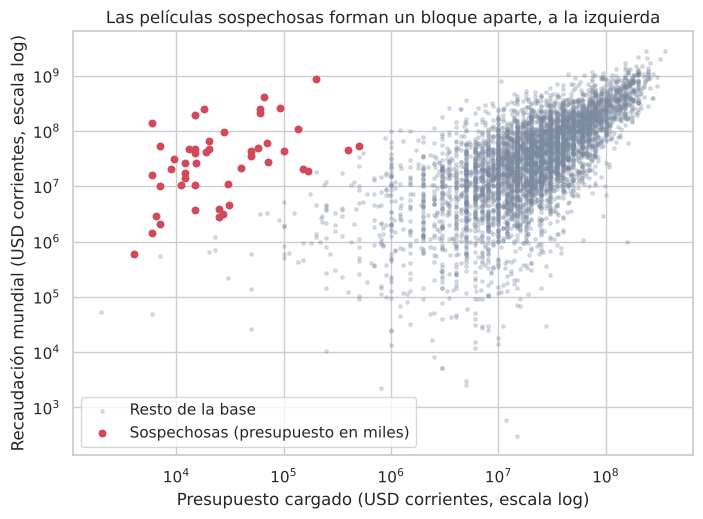

In [11]:
# Gráfico de diagnóstico: presupuesto contra recaudación, en escala logarítmica
figura, eje = plt.subplots(figsize=(8, 5.5))
valido = peliculas["presupuesto_usd"].notna() & (peliculas["recaudacion_mundial_usd"] > 0)
eje.scatter(
    peliculas.loc[valido & ~sospechosas, "presupuesto_usd"],
    peliculas.loc[valido & ~sospechosas, "recaudacion_mundial_usd"],
    s=6,
    alpha=0.25,
    color="#7a8aa0",
    label="Resto de la base",
)
eje.scatter(
    peliculas.loc[sospechosas, "presupuesto_usd"],
    peliculas.loc[sospechosas, "recaudacion_mundial_usd"],
    s=22,
    color="#d1495b",
    label="Sospechosas (presupuesto en miles)",
)
eje.set_xscale("log")
eje.set_yscale("log")
eje.set_xlabel("Presupuesto cargado (USD corrientes, escala log)")
eje.set_ylabel("Recaudación mundial (USD corrientes, escala log)")
eje.set_title("Las películas sospechosas forman un bloque aparte, a la izquierda")
eje.legend()
plt.show()

**Resultado.** 48 películas (0,6% de la base) cumplen la regla de presupuesto menor a USD 1 M y retorno mayor a 100x. El corte no es frágil:
bajarlo a 50x suma 8 películas y subirlo a 200x resta 9. Estas películas son distintas de las realmente baratas: recaudaron una mediana de USD 32,8 M contra 1,5 M de las baratas genuinas
y tienen más del doble de votos (42.000 contra 17.000). Con el presupuesto multiplicado por 1.000 su retorno queda entre 0,35x y 3,16x (cuartiles 25 y 75), casi el mismo rango que el resto de la base (0,72x a 3,65x):
la hipótesis de "presupuesto en miles" explica los datos.

**Es el hallazgo más importante de la limpieza.** Sin esta corrección el retorno medio de la industria sería 26,7x; con ella es 3,3x. La mediana casi no se mueve (1,86x a 1,82x).
Ahí ya se ve por qué el promedio no sirve para decidir en esta industria.

*Limitación.* Dos de las 48 (*Paranormal Activity* y *The Blair Witch Project*) son micropresupuestos reales conocidos que la regla trata como error. Es una decisión conservadora: les quita retorno al terror.

In [12]:
registrar(
    "Presupuesto en miles de dólares (< USD 1 M y retorno > 100x)",
    sospechosas.sum(),
    "Se multiplica por 1.000. Limitación: dos micropresupuestos reales famosos caen en la regla",
)
peliculas["presupuesto_corregido_escala"] = sospechosas  # dejamos marca para poder auditar
peliculas.loc[sospechosas, "presupuesto_usd"] = peliculas.loc[sospechosas, "presupuesto_usd"] * 1000
fotos.append(estado_retorno(peliculas, "4. Presupuestos en escala corregida"))

# Efecto de una decisión discutible: ¿cambia algo si NO corrigiéramos esas filas?
sin_corregir = peliculas.copy()
sin_corregir.loc[sospechosas, "presupuesto_usd"] = (
    sin_corregir.loc[sospechosas, "presupuesto_usd"] / 1000
)
foto_sin = pd.DataFrame([estado_retorno(sin_corregir, "Si NO se corrigiera")]).iloc[0]
foto_con = pd.DataFrame([estado_retorno(peliculas, "Corrigiendo")]).iloc[0]
print(
    f"Retorno medio   : {foto_sin['retorno_medio']:.2f}x sin corregir  vs  {foto_con['retorno_medio']:.2f}x corrigiendo"
)
print(
    f"Retorno mediano : {foto_sin['retorno_mediano']:.2f}x sin corregir  vs  {foto_con['retorno_mediano']:.2f}x corrigiendo"
)

Retorno medio   : 26.70x sin corregir  vs  3.33x corrigiendo
Retorno mediano : 1.86x sin corregir  vs  1.82x corrigiendo


<h3 style='font-weight:bold; color:#0033BB;'>1.7 Normalización de variables categóricas</h3>

Si el mismo género aparece como `Comedia` y `comedia`, `groupby` lo parte en dos filas. La estrategia es una **clave de comparación**
(minúsculas, sin tildes, sin espacios de más) y un diccionario que dice cuál es la forma canónica de cada clave.
Para `productora` no hay un diccionario a mano: se unifica por clave y se elige la grafía más frecuente.

In [13]:
def clave(texto):
    """Minúsculas, sin tildes y sin espacios repetidos: sirve para comparar grafías."""
    sin_tildes = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(sin_tildes.lower().split())


def normalizar(serie, equivalencias, faltante=None):
    """Lleva cada valor a su forma canónica; lo que no está en el diccionario se limpia y se deja."""

    def convertir(valor):
        if pd.isna(valor):
            return faltante
        return equivalencias.get(clave(valor), " ".join(str(valor).split()))

    return serie.map(convertir)


EQUIV_GENERO = {
    "comedia": "Comedia",
    "accion": "Acción",
    "drama": "Drama",
    "policial": "Policial",
    "biografia": "Biografía",
    "aventura": "Aventura",
    "animacion": "Animación",
    "terror": "Terror",
    "fantasia": "Fantasía",
    "misterio": "Misterio",
    "suspenso": "Suspenso",
    "familiar": "Familiar",
    "romance": "Romance",
    "ciencia ficcion": "Ciencia ficción",
    "musical": "Musical",
    "western": "Western",
    "deportiva": "Deportiva",
    "historico": "Histórico",
}
EQUIV_CLASIFICACION = {
    "atp": "ATP",
    "apta todo publico": "ATP",
    "supervision parental": "Supervisión parental",
    "mayores de 13": "Mayores de 13",
    "mayores de 17": "Mayores de 17",
    "solo adultos": "Solo adultos",
    "sin clasificar": "Sin clasificar",
}
EQUIV_PAIS = {
    "ee.uu.": "Estados Unidos",
    "uk": "Reino Unido",
    "canada": "Canadá",
    "japon": "Japón",
    "mexico": "México",
    "espania": "España",
    "alemania occidental": "Alemania",
}


def unificar_por_clave(serie):
    """Para textos sin diccionario (productoras): une grafías y elige la más frecuente."""
    limpia = serie.map(lambda valor: " ".join(str(valor).split()) if pd.notna(valor) else valor)
    claves = limpia.map(lambda valor: clave(valor) if pd.notna(valor) else valor)
    mas_frecuente = limpia.groupby(claves).agg(lambda s: s.value_counts().index[0])
    return limpia.where(limpia.isna(), claves.map(mas_frecuente))


COLUMNAS_CATEGORICAS = ["genero", "clasificacion", "pais_origen", "productora"]
antes_categorias = {columna: peliculas[columna].nunique() for columna in COLUMNAS_CATEGORICAS}
originales_categoricas = peliculas[COLUMNAS_CATEGORICAS].astype(object).fillna("(vacío)")

peliculas["genero"] = normalizar(peliculas["genero"], EQUIV_GENERO, faltante="Sin dato")
# Una clasificación vacía se trata como "Sin clasificar": ya existe esa categoría en la base
peliculas["clasificacion"] = normalizar(
    peliculas["clasificacion"], EQUIV_CLASIFICACION, faltante="Sin clasificar"
)
peliculas["pais_origen"] = normalizar(peliculas["pais_origen"], EQUIV_PAIS, faltante="Sin dato")
peliculas["productora"] = unificar_por_clave(peliculas["productora"])

# es_secuela pasa de "Si"/"No" a booleano; si apareciera otro valor, el assert lo avisa
peliculas["es_secuela"] = peliculas["es_secuela"].map({"Si": True, "No": False})
assert peliculas["es_secuela"].notna().all(), "es_secuela tiene valores fuera de Si/No"
peliculas["es_secuela"] = peliculas["es_secuela"].astype(bool)

despues_categorias = {columna: peliculas[columna].nunique() for columna in COLUMNAS_CATEGORICAS}
display(pd.DataFrame({"antes": antes_categorias, "despues": despues_categorias}))

filas_cambiadas = (
    (peliculas[COLUMNAS_CATEGORICAS].astype(object).fillna("(vacío)") != originales_categoricas)
    .any(axis=1)
    .sum()
)
registrar(
    "Categorías escritas de varias maneras (género, clasificación, país, productora)",
    filas_cambiadas,
    "Se unifican a una grafía canónica; no se pierde ninguna fila",
)

print("\nGéneros después de normalizar:")
print(peliculas["genero"].value_counts().to_string())
print("\nClasificaciones:")
print(peliculas["clasificacion"].value_counts().to_string())

,antes,despues
genero,25,18
clasificacion,10,6
pais_origen,64,58
productora,2744,2382



Géneros después de normalizar:
genero
Comedia            2245
Acción             1705
Drama              1518
Policial            551
Biografía           443
Aventura            427
Animación           338
Terror              322
Fantasía             44
Misterio             20
Suspenso             16
Familiar             11
Ciencia ficción      10
Romance              10
Musical               3
Western               3
Histórico             1
Deportiva             1

Clasificaciones:
clasificacion
Mayores de 17           3697
Mayores de 13           2112
Supervisión parental    1252
Sin clasificar           428
ATP                      153
Solo adultos              26


**Resultado.** Los géneros pasan de 25 a 18 grafías, las clasificaciones de 10 a 6, los países de 64 a 58 y las productoras de 2.744 a 2.382 (en su mayoría espacios sobrantes, como ` Universal Pictures` contra `Universal Pictures`).
Una clasificación vacía se trata como *Sin clasificar*: esa categoría ya existe y el vacío significa lo mismo. *Alemania Occidental* se une a *Alemania* porque son pocas películas y la distinción no aporta al análisis de retorno.
Cambia la grafía de 2.879 filas (37% de la base) pero no se pierde ninguna: son cambios de forma, no de contenido.

<h3 style='font-weight:bold; color:#0033BB;'>1.8 Cobertura temporal</h3>

In [14]:
# Fechas: dos formatos conviven en la columna; probamos cada uno
def parsear_fechas(serie):
    """Parsea AAAA-MM-DD y DD/MM/AAAA. Se verificó que las barras son día/mes (hay días > 12)."""
    formato_iso = pd.to_datetime(serie, format="%Y-%m-%d", errors="coerce")
    formato_latino = pd.to_datetime(serie, format="%d/%m/%Y", errors="coerce")
    return formato_iso.fillna(formato_latino)


peliculas["fecha_estreno"] = parsear_fechas(peliculas["fecha_estreno"])
print("Fechas que no se pudieron parsear:", peliculas["fecha_estreno"].isna().sum())

diferencia_anios = (
    (peliculas["fecha_estreno"].dt.year - peliculas["anio_estreno"]).value_counts().sort_index()
)
print("\nAño de la fecha menos año_estreno (0 = coinciden):")
print(diferencia_anios.head(6).to_string())

Fechas que no se pudieron parsear: 0

Año de la fecha menos año_estreno (0 = coinciden):
0    6371
1    1162
2      89
3      16
4       9
5       4


La fecha de estreno puede caer un año después del `anio_estreno` en parte de la base (estreno en otro país, por ejemplo).
Para deflactar se usa **`anio_estreno`**, que es el año contra el que está medida la columna de dinero. La fecha completa
no se necesita para el análisis.

anio_estreno,1980,1981,1982,1983,1984,1985,1986,2018,2019,2020
peliculas,92.00,113.00,126.00,144.00,168.00,200.00,200.00,200.00,200.00,25.00
pct_sin_presupuesto,49.00,40.00,41.00,38.00,47.00,51.00,50.00,30.00,43.00,40.00


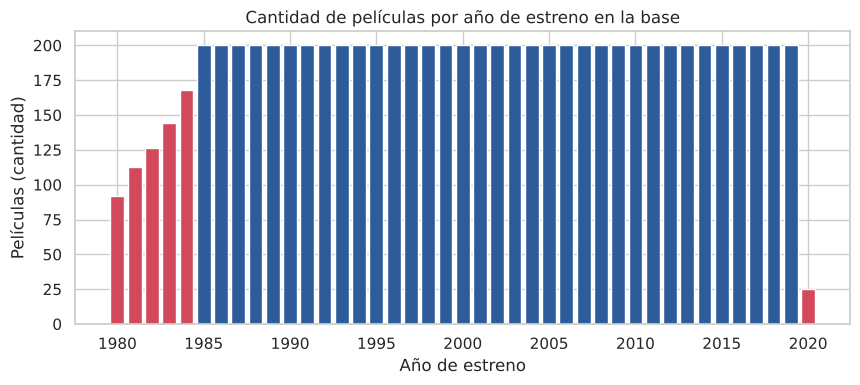

In [15]:
por_anio = peliculas.groupby("anio_estreno").agg(
    peliculas=("id_pelicula", "size"),
    pct_sin_presupuesto=("presupuesto_usd", lambda s: s.isna().mean() * 100),
)
display(por_anio.T.round(0).iloc[:, [0, 1, 2, 3, 4, 5, 6, -3, -2, -1]])

figura, eje = plt.subplots(figsize=(10, 3.8))
colores = [
    "#d1495b" if anio in (1980, 1981, 1982, 1983, 1984, 2020) else "#2e5b9a"
    for anio in por_anio.index
]
eje.bar(por_anio.index, por_anio["peliculas"], color=colores)
eje.set_title("Cantidad de películas por año de estreno en la base")
eje.set_xlabel("Año de estreno")
eje.set_ylabel("Películas (cantidad)")
plt.show()

**Lectura.** Desde 1985 la base tiene unas 200 películas por año, un número casi constante: es una **muestra** de la industria y no un censo, por eso no sirve para decir cuántas películas se estrenan.
Los años 1980 a 1984 están incompletos (92, 113, 126, 144 y 168 películas) y 2020 tiene solo 25 (año parcial). El porcentaje sin presupuesto tampoco es parejo entre años: ronda el 50% a mediados de los 80.

**Decisión.** No se descarta ningún año de la base. Pero 2020 queda afuera de las tablas y gráficos de tendencia, porque 25 películas dan una mediana inestable (un solo punto estiraba todo el eje del gráfico de la sección 3.1).
Los años 1980-84 se usan, con la advertencia de que su mediana es menos confiable. 2020 sí se usa en el conjunto de prueba (2015-2020).

<h3 style='font-weight:bold; color:#0033BB;'>1.9 Películas sin presupuesto: ¿faltan al azar o por una razón?</h3>

Sin presupuesto no hay retorno, así que estas películas **no entran** a ningún cálculo de rentabilidad. Antes de aceptar esa pérdida
hay que saber si es un grupo cualquiera (en cuyo caso descartarlas no sesga nada) o si faltan por una razón (en cuyo caso las conclusiones se sesgan).
Se compara el porcentaje de faltantes por década, país, género y también por la recaudación, que sí está cargada.

In [16]:
peliculas["sin_presupuesto"] = peliculas["presupuesto_usd"].isna()
peliculas["decada"] = (peliculas["anio_estreno"] // 10 * 10).astype(str) + "s"
peliculas["origen"] = np.where(
    peliculas["pais_origen"] == "Estados Unidos", "Estados Unidos", "Resto del mundo"
)

print(
    f"Películas sin presupuesto (ya con los centinelas): {peliculas['sin_presupuesto'].sum():,} "
    f"de {len(peliculas):,} ({peliculas['sin_presupuesto'].mean():.1%})"
)


def pct_faltante_por(columna, minimo=30):
    """% de películas sin presupuesto en cada categoría de `columna`."""
    tabla = peliculas.groupby(columna).agg(
        peliculas=("sin_presupuesto", "size"), pct_sin_presupuesto=("sin_presupuesto", "mean")
    )
    tabla["pct_sin_presupuesto"] *= 100
    return tabla.loc[tabla["peliculas"] >= minimo].sort_values(
        "pct_sin_presupuesto", ascending=False
    )


print("\nPor década")
display(pct_faltante_por("decada", minimo=1).sort_index())
print("Por origen")
display(pct_faltante_por("origen"))
print("Por país de origen (países con 30 o más películas)")
display(pct_faltante_por("pais_origen").head(10))
print("Por género (géneros con 30 o más películas)")
display(pct_faltante_por("genero"))

# Test de independencia chi-cuadrado: ¿las diferencias pueden ser azar?
for columna in ["decada", "origen", "genero"]:
    tabla_cruzada = pd.crosstab(peliculas[columna], peliculas["sin_presupuesto"])
    p_valor = stats.chi2_contingency(tabla_cruzada)[1]
    print(f"Chi-cuadrado sin_presupuesto vs {columna:<7}: p-valor = {p_valor:.2g}")

Películas sin presupuesto (ya con los centinelas): 2,219 de 7,668 (28.9%)

Por década


,peliculas,pct_sin_presupuesto
decada,,
1980s,1643,43.94
1990s,2000,31.55
2000s,2000,18.00
2010s,2000,24.80
2020s,25,40.00


Por origen


,peliculas,pct_sin_presupuesto
origen,,
Resto del mundo,2193,49.38
Estados Unidos,5475,20.75


Por país de origen (países con 30 o más películas)


,peliculas,pct_sin_presupuesto
pais_origen,,
India,62,85.48
Italia,61,68.85
Dinamarca,32,65.62
España,47,63.83
Corea del Sur,35,62.86
Francia,279,62.37
Japón,81,60.49
Australia,92,54.35
Irlanda,43,51.16


Por género (géneros con 30 o más películas)


,peliculas,pct_sin_presupuesto
genero,,
Drama,1518,42.49
Comedia,2245,33.54
Biografía,443,28.89
Policial,551,26.86
Aventura,427,23.89
Animación,338,18.93
Terror,322,18.01
Acción,1705,17.01
Fantasía,44,4.55


Chi-cuadrado sin_presupuesto vs decada : p-valor = 3.1e-68
Chi-cuadrado sin_presupuesto vs origen : p-valor = 1.7e-137
Chi-cuadrado sin_presupuesto vs genero : p-valor = 7.8e-65


In [17]:
# Lo decisivo: ¿cómo son las películas sin presupuesto en las columnas que SÍ conocemos?
comparacion_faltantes = peliculas.groupby("sin_presupuesto").agg(
    peliculas=("id_pelicula", "size"),
    recaudacion_mediana_usd=("recaudacion_mundial_usd", "median"),
    votos_medianos=("cantidad_votos", "median"),
    puntaje_mediano=("puntaje_imdb", "median"),
)
comparacion_faltantes.index = ["Con presupuesto", "Sin presupuesto"]
display(comparacion_faltantes)

peliculas["tramo_recaudacion"] = pd.qcut(
    peliculas["recaudacion_mundial_usd"], 5, labels=["Q1 (menor)", "Q2", "Q3", "Q4", "Q5 (mayor)"]
)
print("% sin presupuesto según el quintil de recaudación:")
display(
    peliculas.groupby("tramo_recaudacion", observed=True)["sin_presupuesto"]
    .mean()
    .mul(100)
    .to_frame("pct_sin_presupuesto")
)

,peliculas,recaudacion_mediana_usd,votos_medianos,puntaje_mediano
Con presupuesto,5449,"36,606,743.00","51,000.00",6.45
Sin presupuesto,2219,"4,150,418.50","8,900.00",6.50


% sin presupuesto según el quintil de recaudación:


,pct_sin_presupuesto
tramo_recaudacion,
Q1 (menor),60.29
Q2,41.24
Q3,24.88
Q4,9.63
Q5 (mayor),3.68


**Lectura.** Faltan 2.219 presupuestos (28,9% de la base, contando los ceros y -1 que eran centinelas). **No faltan al azar:**

- por década: 43,9% en los 80, 31,6% en los 90, 18,0% en los 2000 y 24,8% en los 2010;
- por origen: 49,4% en el resto del mundo contra 20,8% en Estados Unidos (India llega a 85,5%);
- por género: 42,5% en drama y 33,5% en comedia, contra 17,0% en acción y 18,0% en terror;
- los chi-cuadrado dan p-valores menores a 10^-60 en los tres casos: las diferencias no son azar.

Y lo decisivo: las películas sin presupuesto son **chicas**. Su recaudación mediana es USD 4,2 M contra 36,6 M de las que sí lo tienen, y el presupuesto falta en el 60% de las películas del quintil de menor recaudación
contra el 3,7% del quintil de mayor recaudación. Faltan las películas pequeñas, extranjeras, antiguas y de drama o comedia, que son justo donde el fracaso es más frecuente.

**Decisión.** Descartar es inevitable (no se puede inventar un presupuesto), pero no se descarta *en silencio*. Se aplica una **corrección por ponderación** (post-estratificación):
cada película con presupuesto pasa a representar a las que faltan en su mismo grupo, donde el grupo se define por **década de recaudación y país** (EE.UU. contra el resto). Una película de recaudación baja con presupuesto
conocido pesa más que una de recaudación alta, porque en ese tramo faltan muchas más. El supuesto es que, **dada la recaudación y el origen**, los presupuestos faltantes se parecen a los observados. No se puede
verificar con los datos, así que se usa como **escenario de robustez** y no como verdad.

In [18]:
# Ponderadores: 1 / (probabilidad de tener presupuesto dentro de su grupo de recaudación y origen)
peliculas["decil_recaudacion"] = pd.qcut(peliculas["recaudacion_mundial_usd"], 10, labels=False)
tasa_observado = (
    peliculas.assign(observado=~peliculas["sin_presupuesto"])
    .groupby(["decil_recaudacion", "origen"])["observado"]
    .transform("mean")
)
peliculas["peso_faltantes"] = np.where(peliculas["sin_presupuesto"], np.nan, 1 / tasa_observado)


def mediana_ponderada(valores, pesos):
    """Mediana donde cada valor cuenta `pesos` veces."""
    orden = np.argsort(valores.to_numpy())
    valores_ordenados = valores.to_numpy()[orden]
    acumulado = np.cumsum(pesos.to_numpy()[orden])
    acumulado = acumulado / acumulado[-1]
    return valores_ordenados[np.searchsorted(acumulado, 0.5)]


registrar(
    "Películas sin presupuesto (centinelas incluidos)",
    peliculas["sin_presupuesto"].sum(),
    "Se excluyen del cálculo de retorno y se corrige con ponderadores como escenario de robustez",
)

<h2 style='font-weight:bold; color:#003366;'>Etapa 2: Creación de variables</h2>

<h3 style='font-weight:bold; color:#0033BB;'>2.1 Dólares constantes</h3>

**Qué hace la operación.** El IPC mide cuánto cuesta una canasta fija de bienes en cada año. Si el IPC de 1985 es 107,6 y el de 2020 es 258,8,
la misma canasta cuesta 2,4 veces más en 2020, así que un dólar de 1985 compra lo que 2,4 dólares de 2020. Para llevar un monto de cualquier año a dólares de 2020 se multiplica por

`factor = IPC(2020) / IPC(año de estreno)`

El resultado **no cambia lo que se compró**, solo la unidad de medida: pasa de "dólares del año X" a "dólares de 2020", y con eso dos películas de distintas épocas se pueden comparar.

In [19]:
peliculas = peliculas.merge(
    ipc.rename(columns={"anio": "anio_estreno"}), on="anio_estreno", how="left", validate="m:1"
)
ipc_base = ipc.loc[ipc["anio"] == ANIO_BASE, "ipc_eeuu"].iloc[0]
peliculas["factor_inflacion"] = ipc_base / peliculas["ipc_eeuu"]

peliculas["presupuesto_real"] = peliculas["presupuesto_usd"] * peliculas["factor_inflacion"]
peliculas["recaudacion_real"] = peliculas["recaudacion_mundial_usd"] * peliculas["factor_inflacion"]

print(f"Películas sin IPC asignado: {peliculas['ipc_eeuu'].isna().sum()}")
display(
    peliculas.loc[
        peliculas["titulo"].isin(["E.T. the Extra-Terrestrial", "Jurassic World", "Titanic"]),
        [
            "titulo",
            "anio_estreno",
            "factor_inflacion",
            "recaudacion_mundial_usd",
            "recaudacion_real",
        ],
    ]
)

Películas sin IPC asignado: 0


,titulo,anio_estreno,factor_inflacion,recaudacion_mundial_usd,recaudacion_real
209,E.T. the Extra-Terrestrial,1982,2.68,"792,910,554.00","2,126,479,288.86"
3045,Titanic,1997,1.61,"2,201,647,264.00","3,550,070,479.27"
6653,Jurassic World,2015,1.09,"1,670,516,444.00","1,824,175,762.48"


*E.T.* recaudó USD 793 M corrientes en 1982 y esa cifra, llevada a dólares de 2020, es casi 2,7 veces más grande. Es la diferencia entre
mirar el cartel y mirar el poder de compra.

<h3 style='font-weight:bold; color:#0033BB;'>2.2 Retorno y regla del 2,5×</h3>

In [20]:
peliculas["roi"] = peliculas["recaudacion_mundial_usd"] / peliculas["presupuesto_usd"]
peliculas["recupera"] = np.where(
    peliculas["roi"].notna(), peliculas["roi"] >= UMBRAL_RECUPERO, np.nan
)
peliculas["no_recupera"] = (
    1 - peliculas["recupera"]
)  # 1 = perdió plata en salas (para promediar como probabilidad)

# Comprobación: el retorno es el mismo en dólares corrientes y constantes
roi_real = peliculas["recaudacion_real"] / peliculas["presupuesto_real"]
print(
    "Máxima diferencia entre retorno corriente y retorno en constantes:",
    f"{(peliculas['roi'] - roi_real).abs().max():.1e}",
)

Máxima diferencia entre retorno corriente y retorno en constantes: 1.4e-14


**Una propiedad útil que hay que entender.** El retorno es un cociente entre dos montos del *mismo* año, así que el factor de inflación se cancela:
el retorno corriente y el constante son idénticos (la comprobación de arriba lo muestra). La inflación importa para comparar **montos** entre épocas
(¿creció la industria?, ¿cuánto cuesta una película típica hoy?) pero no para comparar **retornos**.

<h3 style='font-weight:bold; color:#0033BB;'>2.3 Variables adicionales</h3>

In [21]:
# Tramo de presupuesto en dólares constantes (para poder comparar películas de distinta época)
CORTES_PRESUPUESTO = [0, 5e6, 20e6, 50e6, 100e6, np.inf]
ETIQUETAS_PRESUPUESTO = ["Menos de 5 M", "5 a 20 M", "20 a 50 M", "50 a 100 M", "Más de 100 M"]
peliculas["tramo_presupuesto"] = pd.cut(
    peliculas["presupuesto_real"], CORTES_PRESUPUESTO, labels=ETIQUETAS_PRESUPUESTO
)
peliculas["franquicia"] = np.where(peliculas["es_secuela"], "Franquicia", "Original")
peliculas["periodo"] = np.where(
    peliculas["anio_estreno"] <= ANIO_CORTE, "entrenamiento (hasta 2014)", "prueba (2015-2020)"
)
peliculas["log_votos"] = np.log10(peliculas["cantidad_votos"])
peliculas["log_roi"] = np.log10(peliculas["roi"])

# Agrupamos los géneros chicos (menos de MIN_PELICULAS con retorno) para que los segmentos se puedan interpretar
conteo_genero = peliculas.loc[peliculas["roi"].notna(), "genero"].value_counts()
generos_chicos = conteo_genero[conteo_genero < MIN_PELICULAS].index
peliculas["genero_agrupado"] = np.where(
    peliculas["genero"].isin(generos_chicos), "Otros géneros", peliculas["genero"]
)

# Base de trabajo para todo lo que sea retorno: películas con presupuesto y recaudación
analisis = peliculas.loc[peliculas["roi"].notna()].copy()
print(f"Películas en la base limpia      : {len(peliculas):,}")
print(
    f"Películas con retorno calculable : {len(analisis):,} ({len(analisis) / len(peliculas):.1%})"
)
print(f"Géneros agrupados en 'Otros'     : {', '.join(generos_chicos)}")

Películas en la base limpia      : 7,668
Películas con retorno calculable : 5,389 (70.3%)
Géneros agrupados en 'Otros'     : Misterio, Suspenso, Ciencia ficción, Romance, Familiar, Western


In [22]:
# Efecto de los faltantes de presupuesto sobre las conclusiones: observado contra ajustado por ponderación
def resumen_ajustado(df):
    """Mediana y probabilidad de perder, sin ajustar y ajustando por los faltantes de presupuesto."""
    return {
        "mediana_observada": df["roi"].median(),
        "mediana_ajustada": mediana_ponderada(df["roi"], df["peso_faltantes"]),
        "p_perder_observada": df["no_recupera"].mean(),
        "p_perder_ajustada": np.average(df["no_recupera"], weights=df["peso_faltantes"]),
    }


print("Toda la industria:")
display(pd.Series(resumen_ajustado(analisis)).to_frame("valor").T)

por_genero_ajuste = pd.DataFrame(
    {genero: resumen_ajustado(grupo) for genero, grupo in analisis.groupby("genero_agrupado")}
).T
rho, _ = stats.spearmanr(
    por_genero_ajuste["mediana_observada"], por_genero_ajuste["mediana_ajustada"]
)
print(f"Correlación de rangos del ranking de géneros, observado contra ajustado: {rho:.2f}")
display(por_genero_ajuste.sort_values("mediana_observada", ascending=False))

Toda la industria:


,mediana_observada,mediana_ajustada,p_perder_observada,p_perder_ajustada
valor,1.82,1.34,0.61,0.68


Correlación de rangos del ranking de géneros, observado contra ajustado: 0.72


,mediana_observada,mediana_ajustada,p_perder_observada,p_perder_ajustada
Terror,3.05,2.37,0.43,0.52
Animación,2.92,2.67,0.42,0.48
Fantasía,2.14,1.25,0.57,0.68
Acción,1.87,1.58,0.63,0.68
Otros géneros,1.83,0.79,0.61,0.71
Aventura,1.82,1.23,0.61,0.68
Comedia,1.78,1.30,0.62,0.68
Drama,1.53,0.92,0.63,0.72
Biografía,1.48,1.15,0.68,0.74
Policial,1.30,0.81,0.71,0.78


**Efecto de la decisión sobre las conclusiones.** Trabajar solo con las películas que tienen presupuesto (70,3% de la base) **sobreestima el desempeño de la industria**:
la mediana del retorno pasa de 1,82x (observada) a 1,34x (ajustada) y la probabilidad de perder plata sube de 61% a 68%.

Lo que **sí sobrevive** es el orden: Animación y Terror siguen arriba en los dos escenarios y Policial y Drama siguen abajo (correlación de rangos entre ambos rankings de géneros: 0,72).
Por eso el resto del notebook muestra el número observado **y** el ajustado cuando importa. Las conclusiones sobre *qué clase de película es mejor* son más firmes que las conclusiones sobre *cuánto rinde en términos absolutos*.
También ayuda que la población analizada, las películas con presupuesto informado, sea mayormente grande y estadounidense, o sea el universo donde invertiría el fondo.

In [23]:
# Cierre de la etapa 1: bitácora de cambios y efecto sobre el retorno
bitacora_df = pd.DataFrame(bitacora)
display(bitacora_df.style.format({"pct_base_inicial": "{:.2f}%"}))
print("\nEl retorno de la industria, antes y después de cada corrección:")
display(pd.DataFrame(fotos).set_index("etapa"))
bitacora_df.to_csv(CARPETA_SALIDAS / "bitacora_limpieza.csv", index=False)

,paso,filas_afectadas,pct_base_inicial,decision
0,Filas exactamente duplicadas,58,0.75%,Se borran: carga doble del mismo registro
1,Películas repetidas con presupuesto distinto,14,0.18%,"Se conserva el id original (<90000), cuyo presupuesto es redondo como el resto de la base"
2,"Centinela en duracion_minutos ([0, 999])",34,0.44%,"Se reemplaza por NaN: es un 'no sé', no un dato"
3,Centinela en puntaje_imdb ([0]),22,0.28%,"Se reemplaza por NaN: es un 'no sé', no un dato"
4,"Centinela en presupuesto_usd ([0, -1])",48,0.62%,"Se reemplaza por NaN: es un 'no sé', no un dato"
5,Recaudación con signo negativo,11,0.14%,Se pasa a valor absoluto: magnitud coherente con una película real
6,Presupuesto en miles de dólares (< USD 1 M y retorno > 100x),48,0.62%,Se multiplica por 1.000. Limitación: dos micropresupuestos reales famosos caen en la regla
7,"Categorías escritas de varias maneras (género, clasificación, país, productora)",2879,37.20%,Se unifican a una grafía canónica; no se pierde ninguna fila
8,Películas sin presupuesto (centinelas incluidos),2219,28.67%,Se excluyen del cálculo de retorno y se corrige con ponderadores como escenario de robustez



El retorno de la industria, antes y después de cada corrección:


,filas,con_retorno_calculable,retorno_medio,retorno_mediano,pct_recupera
etapa,,,,,
0. Base cruda,7740,5443,26.46,1.86,39.17
1. Sin duplicados exactos,7682,5403,26.63,1.86,39.18
2. Sin películas repetidas,7668,5389,26.70,1.86,39.23
3. Sin centinelas ni signos,7668,5389,26.70,1.86,39.27
4. Presupuestos en escala corregida,7668,5389,3.33,1.82,38.67


**Lectura de la bitácora.** Casi todas las correcciones afectan menos del 1% de la base y no mueven el retorno mediano (se mantiene en 1,86x hasta la corrección de escala y queda en 1,82x).
Tres cambios pesan más: 2.879 filas (37%) cambian de grafía sin perder contenido; 2.219 presupuestos faltantes (el 28,7% de la base inicial) que se excluyen del cálculo de retorno y se corrigen con ponderadores;
y 48 presupuestos (0,6%) cambian de escala, que es la corrección que más mueve el retorno **medio** (de 26,7x a 3,3x). Conclusión metodológica: el retorno mediano es robusto a la limpieza y el medio no.

<h2 style='font-weight:bold; color:#003366;'>Etapa 3: Análisis de negocio</h2>

<h3 style='font-weight:bold; color:#0033BB;'>3.1 ¿La industria creció?</h3>

Se usa la **mediana** de la recaudación de las películas de cada año, no el total, porque la base tiene unas 200 películas por año
(no es un censo de la industria) y el total solo reflejaría cuántas películas hay cargadas. La mediana responde a otra pregunta: ¿cuánto recauda una película típica?

,peliculas,mediana_corriente_M,mediana_constante_M
decada,,,
1980s,1521,8.62,20.92
1990s,1957,12.87,22.13
2000s,1994,40.41,53.42
2010s,1992,41.67,45.79


Crecimiento de la mediana entre la década de 1980 y la de 2010: +383% corriente, +119% constante
Inflación de EE.UU. entre 1985 y 2015 (IPC): +120%


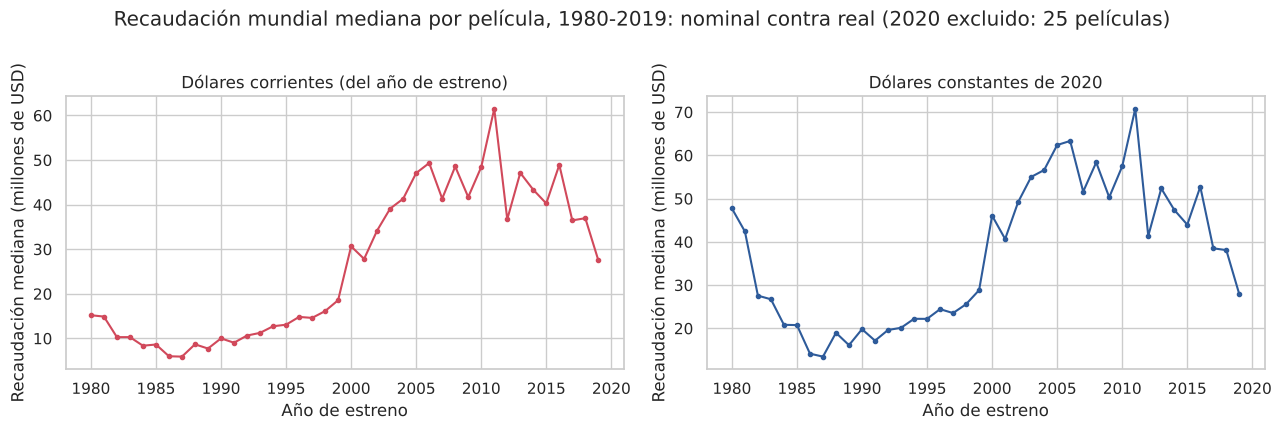

In [24]:
con_recaudacion = peliculas.dropna(subset=["recaudacion_mundial_usd"])
serie_anual = con_recaudacion.groupby("anio_estreno").agg(
    peliculas=("id_pelicula", "size"),
    mediana_corriente=("recaudacion_mundial_usd", "median"),
    mediana_constante=("recaudacion_real", "median"),
)

# Por década, sin 2020 (solo 25 películas, año incompleto)
por_decada = (
    con_recaudacion.loc[con_recaudacion["anio_estreno"] < 2020]
    .groupby("decada")
    .agg(
        peliculas=("id_pelicula", "size"),
        mediana_corriente_M=("recaudacion_mundial_usd", lambda s: s.median() / 1e6),
        mediana_constante_M=("recaudacion_real", lambda s: s.median() / 1e6),
    )
)
display(por_decada)

crecimiento_corriente = (
    por_decada["mediana_corriente_M"].iloc[-1] / por_decada["mediana_corriente_M"].iloc[0] - 1
)
crecimiento_constante = (
    por_decada["mediana_constante_M"].iloc[-1] / por_decada["mediana_constante_M"].iloc[0] - 1
)
inflacion_acumulada = (
    ipc.loc[ipc["anio"] == 2015, "ipc_eeuu"].iloc[0]
    / ipc.loc[ipc["anio"] == 1985, "ipc_eeuu"].iloc[0]
    - 1
)
print(
    f"Crecimiento de la mediana entre la década de 1980 y la de 2010: {crecimiento_corriente:+.0%} corriente, {crecimiento_constante:+.0%} constante"
)
print(f"Inflación de EE.UU. entre 1985 y 2015 (IPC): {inflacion_acumulada:+.0%}")

serie_anual_completa = serie_anual.loc[
    serie_anual.index < 2020
]  # 2020 tiene solo 25 películas y distorsiona el eje
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for eje, columna, titulo, color in [
    (ejes[0], "mediana_corriente", "Dólares corrientes (del año de estreno)", "#d1495b"),
    (ejes[1], "mediana_constante", "Dólares constantes de 2020", "#2e5b9a"),
]:
    eje.plot(
        serie_anual_completa.index,
        serie_anual_completa[columna] / 1e6,
        color=color,
        marker="o",
        markersize=3,
    )
    eje.set_title(titulo)
    eje.set_xlabel("Año de estreno")
    eje.set_ylabel("Recaudación mediana (millones de USD)")
figura.suptitle(
    "Recaudación mundial mediana por película, 1980-2019: nominal contra real (2020 excluido: 25 películas)",
    y=1.02,
)
plt.tight_layout()
guardar_figura(figura, "01_evolucion_nominal_vs_real")
plt.show()

**Lectura.** En dólares corrientes, la recaudación mediana por película pasa de USD 8,6 M en la década de 1980 a USD 41,7 M en la de 2010: **+383%**.
En dólares constantes de 2020 el salto es de 20,9 M a 45,8 M: **+119%**. La inflación acumulada de EE.UU. entre 1985 y 2015 fue de +120%, así que los precios más que se duplicaron.
Aproximadamente la mitad del salto nominal (en términos logarítmicos) es inflación y no crecimiento real.

**Conclusión sobre la inflación.** Comparar dólares corrientes de épocas distintas exagera el crecimiento: el gráfico de la izquierda muestra una industria que casi se quintuplica y el de la derecha, una película típica que **se duplica**.
Además el crecimiento real se concentra entre los 90 y los 2000: la mediana real de los 2010 (45,8 M) es 14% menor que la de los 2000 (53,4 M). Sin el IPC se concluiría que la industria sigue acelerando, y la película típica dejó de crecer.
Advertencia: la base es una muestra de unas 200 películas por año, así que esto habla de la película típica de la base, no del tamaño de la industria.

<h3 style='font-weight:bold; color:#0033BB;'>3.2 ¿Cuánto rinde cada tipo de película?</h3>

In [25]:
def metricas_segmento(df, columna):
    """Retorno medio y mediano, probabilidad de perder y peor decil por categoría de `columna`.

    Además calcula mediana y probabilidad de perder 'ajustadas' por los faltantes de presupuesto.
    """
    filas = []
    for valor, grupo in df.groupby(columna, observed=True):
        filas.append(
            {
                "familia": columna,
                "segmento": str(valor),
                "n": len(grupo),
                "retorno_medio": grupo["roi"].mean(),
                "retorno_mediano": grupo["roi"].median(),
                "p_perder": grupo["no_recupera"].mean(),
                "peor_decil": grupo["roi"].quantile(0.10),
                "retorno_mediano_ajustado": mediana_ponderada(
                    grupo["roi"], grupo["peso_faltantes"]
                ),
                "p_perder_ajustada": np.average(
                    grupo["no_recupera"], weights=grupo["peso_faltantes"]
                ),
            }
        )
    return pd.DataFrame(filas).set_index("segmento").drop(columns="familia")


por_genero = metricas_segmento(analisis, "genero_agrupado").sort_values(
    "retorno_mediano", ascending=False
)
por_genero["media_sobre_mediana"] = por_genero["retorno_medio"] / por_genero["retorno_mediano"]
print(
    "Retorno por género (ordenado por mediana). 'media_sobre_mediana' mide cuánto infla el promedio."
)
display(por_genero[["n", "retorno_medio", "retorno_mediano", "media_sobre_mediana"]])

print(
    f"Toda la industria: retorno medio {analisis['roi'].mean():.2f}x | mediano {analisis['roi'].median():.2f}x"
)

Retorno por género (ordenado por mediana). 'media_sobre_mediana' mide cuánto infla el promedio.


,n,retorno_medio,retorno_mediano,media_sobre_mediana
segmento,,,,
Terror,254,8.18,3.05,2.68
Animación,273,4.00,2.92,1.37
Fantasía,42,2.52,2.14,1.17
Acción,1405,2.71,1.87,1.45
Otros géneros,41,4.41,1.83,2.41
Aventura,323,2.80,1.82,1.54
Comedia,1479,3.34,1.78,1.88
Drama,862,3.58,1.53,2.34
Biografía,312,2.71,1.48,1.84


Toda la industria: retorno medio 3.33x | mediano 1.82x


**¿Quién rompe el promedio?** Se miran las películas con retorno más alto y cuánto del retorno total de cada género explican unas pocas.

In [26]:
columnas_ver = ["titulo", "anio_estreno", "genero", "presupuesto_real", "recaudacion_real", "roi"]
top_retorno = analisis.sort_values("roi", ascending=False)[columnas_ver].head(12)
display(
    top_retorno.assign(
        presupuesto_real=lambda t: t["presupuesto_real"] / 1e6,
        recaudacion_real=lambda t: t["recaudacion_real"] / 1e6,
    ).rename(columns={"presupuesto_real": "presup_M_2020", "recaudacion_real": "recaud_M_2020"})
)


def concentracion_top(grupo, cantidad=5):
    """Qué fracción de la suma de retornos del grupo aportan sus `cantidad` mejores películas."""
    retornos = grupo["roi"].sort_values(ascending=False)
    return retornos.head(cantidad).sum() / retornos.sum()


concentracion = analisis.groupby("genero_agrupado").apply(concentracion_top, include_groups=False)
print("Fracción de la suma de retornos que explican las 5 mejores películas de cada género:")
print(concentracion.sort_values(ascending=False).round(2).head(5).to_string())

# Si sacamos las 5 mejores de cada género, ¿cómo queda el promedio?
sin_top5 = (
    analisis.sort_values("roi", ascending=False)
    .groupby("genero_agrupado")
    .apply(lambda g: g.iloc[5:], include_groups=False)
)
promedio_sin_top5 = sin_top5.groupby(level=0)["roi"].mean()
comparacion_promedio = pd.DataFrame(
    {
        "promedio": por_genero["retorno_medio"],
        "promedio_sin_top5": promedio_sin_top5,
        "mediana": por_genero["retorno_mediano"],
    }
)
display(comparacion_promedio.sort_values("promedio", ascending=False).head(6))

,titulo,anio_estreno,genero,presup_M_2020,recaud_M_2020,roi
6237,The Devil Inside,2012,Terror,1.13,114.70,101.76
6614,The Quiet Ones,2014,Terror,0.22,19.50,89.18
4456,Saw,2004,Terror,1.64,142.36,86.59
7330,Searching,2018,Drama,0.91,77.78,85.75
4507,Primer,2004,Drama,0.01,0.75,77.92
209,E.T. the Extra-Terrestrial,1982,Familiar,28.16,"2,126.48",75.52
4080,My Big Fat Greek Wedding,2002,Comedia,7.19,530.47,73.75
3089,The Full Monty,1997,Comedia,5.64,415.92,73.70
5,Friday the 13th,1980,Terror,1.73,124.86,72.28
5406,Fireproof,2008,Drama,0.60,40.24,66.95


Fracción de la suma de retornos que explican las 5 mejores películas de cada género:
genero_agrupado
Otros géneros   0.62
Fantasía        0.33
Terror          0.20
Policial        0.12
Animación       0.11


,promedio,promedio_sin_top5,mediana
Terror,8.18,6.67,3.05
Otros géneros,4.41,1.89,1.83
Animación,4.00,3.60,2.92
Drama,3.58,3.22,1.53
Comedia,3.34,3.14,1.78
Aventura,2.80,2.56,1.82


**Lectura.** En toda la industria el retorno medio es 3,33x y el mediano 1,82x. En Terror la diferencia es de 2,7 veces (8,18x contra 3,05x) y en Drama de 2,3 veces (3,58x contra 1,53x).

**¿Error de carga o realidad del negocio?** Se miraron las películas que rompen el promedio. Después de corregir la escala de los presupuestos, las de mayor retorno son *The Devil Inside* (102x), *The Quiet Ones* (89x), *Saw* (87x),
*Searching* (86x), *Primer* (78x), *E.T.* (75x), *My Big Fat Greek Wedding* (74x), *The Full Monty* (74x) y *Friday the 13th* (72x). Presupuestos y recaudaciones son coherentes entre sí (películas de muy bajo costo que recaudan decenas o cientos de millones):
**son la realidad del negocio, no errores**. Se conservan. Esto es el corazón de la industria: pocas películas muy baratas con retornos enormes que arrastran el promedio, y una mayoría que no recupera.
Por eso se usan medianas y probabilidades de pérdida en lugar de promedios. En Terror las 5 mejores películas explican el 20% de la suma de retornos, y aun sin ellas el promedio (6,67x) sigue siendo el doble de la mediana: la cola es ancha y no son tres casos aislados.

**Otras categorías**: clasificación por edades, origen y franquicia.

In [27]:
por_clasificacion = metricas_segmento(analisis, "clasificacion").sort_values(
    "retorno_mediano", ascending=False
)
por_franquicia = metricas_segmento(analisis, "franquicia").sort_values(
    "retorno_mediano", ascending=False
)
por_origen = metricas_segmento(analisis, "origen").sort_values("retorno_mediano", ascending=False)
paises_grandes = analisis["pais_origen"].value_counts()
paises_grandes = paises_grandes[paises_grandes >= MIN_PELICULAS].index
por_pais = metricas_segmento(
    analisis[analisis["pais_origen"].isin(paises_grandes)], "pais_origen"
).sort_values("retorno_mediano", ascending=False)

columnas_tabla = ["n", "retorno_medio", "retorno_mediano", "p_perder", "peor_decil"]
for nombre, tabla in [
    ("Clasificación por edades", por_clasificacion),
    ("Franquicia", por_franquicia),
    ("Origen", por_origen),
    ("País (30 o más películas)", por_pais),
]:
    print(nombre)
    display(tabla[columnas_tabla])

Clasificación por edades


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
segmento,,,,,
ATP,110,4.19,2.69,0.48,0.48
Mayores de 13,1713,3.32,2.07,0.58,0.41
Supervisión parental,898,3.34,2.03,0.59,0.35
Solo adultos,13,2.73,1.61,0.62,0.32
Mayores de 17,2579,3.28,1.55,0.65,0.20
Sin clasificar,76,3.89,1.02,0.67,0.04


Franquicia


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
segmento,,,,,
Franquicia,573,4.22,2.97,0.41,0.77
Original,4816,3.22,1.68,0.64,0.25


Origen


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
segmento,,,,,
Estados Unidos,4290,3.39,1.95,0.60,0.30
Resto del mundo,1099,3.10,1.33,0.68,0.16


País (30 o más películas)


,n,retorno_medio,retorno_mediano,p_perder,peor_decil
segmento,,,,,
Japón,31,4.45,2.79,0.48,0.25
Estados Unidos,4290,3.39,1.95,0.60,0.30
Australia,42,4.25,1.53,0.60,0.21
Reino Unido,489,2.88,1.30,0.70,0.17
Francia,105,2.69,1.15,0.75,0.09
Alemania,82,2.09,1.04,0.78,0.17
Canadá,111,3.79,0.83,0.72,0.25


**Lectura.**

- **Clasificación por edades.** La clasificación **ATP** tiene la mediana más alta (2,69x, 48% de pérdida, pero solo 110 películas); le siguen *Mayores de 13* y *Supervisión parental* (2,07x y 2,03x, 58% y 59% de pérdida).
  *Mayores de 17*, que es la categoría más grande (2.579 películas), rinde 1,55x y pierde en 65% de los casos. *Sin clasificar* es la peor (1,02x). Mientras más amplia la audiencia posible, mejor el perfil.
- **Franquicia.** Las franquicias tienen una mediana de 2,97x y pierden en 41% de los casos, contra 1,68x y 64% de las películas originales. El peor decil de una franquicia es 0,77x contra 0,25x en una original.
- **Origen.** Las películas estadounidenses rinden 1,95x (60% de pérdida) y las del resto del mundo 1,33x (68%). Entre los países con 30 películas o más, Reino Unido (1,30x), Francia (1,15x) y Alemania (1,04x) quedan por debajo.
  Japón sale primero con 2,79x pero con solo 31 películas, así que no se interpreta.

Dos cautelas. La franquicia existe porque la película anterior funcionó (sesgo de supervivencia), y el fondo tendría que comprar o asociarse con los derechos. Y el origen está muy afectado por los faltantes: para el resto del mundo falta el presupuesto del 49% de las películas.

**Puntaje de IMDb y retorno.** Se usa correlación de Spearman (por rangos) porque el retorno tiene una cola muy larga y Pearson sería arrastrado por unos pocos casos.

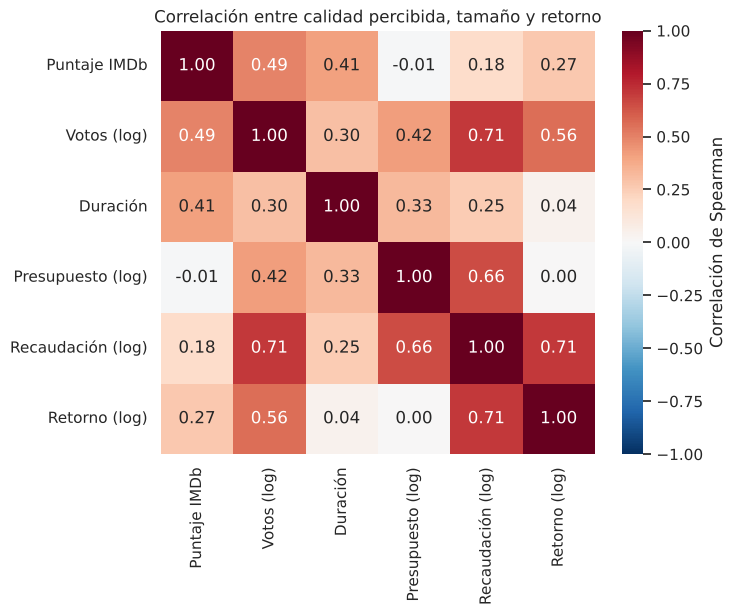

Retorno por tramo de puntaje IMDb


,n,mediana,p_perder
puntaje_imdb,,,
menos de 5,418,0.99,0.75
5 a 6,1312,1.37,0.71
6 a 7,2294,1.76,0.64
7 a 8,1212,2.80,0.46
8 o más,135,5.04,0.21


In [28]:
columnas_corr = [
    "puntaje_imdb",
    "log_votos",
    "duracion_minutos",
    "presupuesto_real",
    "recaudacion_real",
    "roi",
]
base_corr = analisis[columnas_corr].copy()
base_corr["presupuesto_real"] = np.log10(base_corr["presupuesto_real"])
base_corr["recaudacion_real"] = np.log10(base_corr["recaudacion_real"])
base_corr["roi"] = np.log10(base_corr["roi"])
base_corr.columns = [
    "Puntaje IMDb",
    "Votos (log)",
    "Duración",
    "Presupuesto (log)",
    "Recaudación (log)",
    "Retorno (log)",
]
matriz = base_corr.corr(method="spearman")

figura, eje = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    matriz,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    ax=eje,
    cbar_kws={"label": "Correlación de Spearman"},
)
eje.set_title("Correlación entre calidad percibida, tamaño y retorno")
guardar_figura(figura, "02_mapa_calor_correlaciones")
plt.show()

print("Retorno por tramo de puntaje IMDb")
tramos_imdb = pd.cut(
    analisis["puntaje_imdb"],
    [0, 5, 6, 7, 8, 10],
    labels=["menos de 5", "5 a 6", "6 a 7", "7 a 8", "8 o más"],
)
display(
    analisis.groupby(tramos_imdb, observed=True)["roi"].agg(
        n="size", mediana="median", p_perder=lambda s: (s < UMBRAL_RECUPERO).mean()
    )
)

**Lectura.** El puntaje de IMDb tiene una correlación de Spearman de **0,27** con el retorno: positiva pero modesta. Las películas de menos de 5 puntos rinden 0,99x y pierden en 75% de los casos; las de 8 o más rinden 5,04x y pierden en 21%.
Dos cosas más del mapa de calor: el **presupuesto no se correlaciona con el retorno** (0,00), o sea que gastar más no compra un múltiplo mayor aunque sí una recaudación mayor (0,66); y los votos tienen 0,56 con el retorno, pero son consecuencia del éxito.

**Para qué sirve y para qué no.** El puntaje se conoce *después* del estreno: confirma que la calidad importa, pero no se puede usar para decidir qué película financiar. Es una variable descriptiva, no un criterio de selección.

<h3 style='font-weight:bold; color:#0033BB;'>3.3 ¿Dónde está el riesgo?</h3>

Para cada segmento se calcula la mediana del retorno, la **probabilidad de perder plata** (retorno menor a 2,5×) y el **retorno del peor decil**
(el retorno por debajo del cual cae el 10% peor de las películas del segmento). Se incluyen también las versiones ajustadas por los faltantes de presupuesto.
Solo se analizan segmentos con al menos 30 películas, porque con menos una probabilidad no es estable.

In [29]:
conteo_productora = analisis["productora"].value_counts()
analisis["productora_top"] = analisis["productora"].where(
    analisis["productora"].map(conteo_productora) >= 40
)
FAMILIAS = [
    "genero_agrupado",
    "clasificacion",
    "franquicia",
    "tramo_presupuesto",
    "decada",
    "origen",
    "productora_top",
]

segmentos = pd.concat(
    [metricas_segmento(analisis, familia).assign(familia=familia) for familia in FAMILIAS]
)
segmentos = segmentos.loc[segmentos["n"] >= MIN_PELICULAS].copy()
segmentos["etiqueta"] = (
    segmentos["familia"].str.replace("_top", "").str.replace("_agrupado", "")
    + ": "
    + segmentos.index
)
segmentos = segmentos.reset_index(drop=True)


def dominadores_de(fila, tabla):
    """Cantidad de segmentos que tienen mejor mediana Y menor probabilidad de perder (al menos uno estrictamente)."""
    mejor_o_igual = (tabla["retorno_mediano"] >= fila["retorno_mediano"]) & (
        tabla["p_perder"] <= fila["p_perder"]
    )
    estrictamente = (tabla["retorno_mediano"] > fila["retorno_mediano"]) | (
        tabla["p_perder"] < fila["p_perder"]
    )
    return int((mejor_o_igual & estrictamente).sum())


segmentos["dominado_por"] = segmentos.apply(dominadores_de, axis=1, tabla=segmentos)
segmentos["domina_a"] = [
    int(
        (
            (fila["retorno_mediano"] >= segmentos["retorno_mediano"])
            & (fila["p_perder"] <= segmentos["p_perder"])
            & (
                (fila["retorno_mediano"] > segmentos["retorno_mediano"])
                | (fila["p_perder"] < segmentos["p_perder"])
            )
        ).sum()
    )
    for _, fila in segmentos.iterrows()
]
segmentos["en_frontera"] = segmentos["dominado_por"] == 0
print(f"Segmentos analizados: {len(segmentos)} (de {len(FAMILIAS)} familias)")

columnas_riesgo = [
    "etiqueta",
    "n",
    "retorno_mediano",
    "p_perder",
    "peor_decil",
    "retorno_mediano_ajustado",
    "p_perder_ajustada",
    "domina_a",
]
print("\nSegmentos NO dominados (la frontera de riesgo y retorno):")
display(
    segmentos.loc[segmentos["en_frontera"], columnas_riesgo].sort_values(
        "retorno_mediano", ascending=False
    )
)
print("Los 8 segmentos con peor perfil (más dominados):")
display(
    segmentos.sort_values(["dominado_por", "retorno_mediano"], ascending=[False, True])[
        columnas_riesgo + ["dominado_por"]
    ].head(8)
)
segmentos.to_csv(CARPETA_SALIDAS / "segmentos_riesgo_retorno.csv", index=False)

Segmentos analizados: 49 (de 7 familias)

Segmentos NO dominados (la frontera de riesgo y retorno):


,etiqueta,n,retorno_mediano,p_perder,peor_decil,retorno_mediano_ajustado,p_perder_ajustada,domina_a
17,tramo_presupuesto: Menos de 5 M,387,3.34,0.44,0.18,2.06,0.54,44
34,productora: Fox Searchlight Pictures,48,3.23,0.44,1.01,2.61,0.49,44
9,genero: Terror,254,3.05,0.43,0.43,2.37,0.52,44
15,franquicia: Franquicia,573,2.97,0.41,0.77,2.68,0.47,45


Los 8 segmentos con peor perfil (más dominados):


,etiqueta,n,retorno_mediano,p_perder,peor_decil,retorno_mediano_ajustado,p_perder_ajustada,domina_a,dominado_por
28,productora: Castle Rock Entertainment,45,1.00,0.80,0.25,0.72,0.85,0,48
23,decada: 1990s,1357,1.15,0.72,0.16,0.73,0.78,1,45
8,genero: Policial,398,1.30,0.71,0.16,0.81,0.78,2,44
37,productora: Miramax,66,1.08,0.70,0.09,0.77,0.77,1,43
36,productora: Metro-Goldwyn-Mayer (MGM),99,1.32,0.68,0.30,1.08,0.72,4,40
27,origen: Resto del mundo,1099,1.33,0.68,0.16,0.74,0.78,4,40
39,productora: Orion Pictures,46,1.38,0.70,0.18,1.20,0.75,4,40
13,clasificacion: Sin clasificar,76,1.02,0.67,0.04,0.42,0.76,1,39


**Lectura.** De los 49 segmentos analizados (siete familias, 30 películas o más cada uno), solo **cuatro no están dominados** por ningún otro:

| Segmento | n | Mediana | Prob. de perder | Peor decil |
|---|---|---|---|---|
| Presupuesto menor a 5 M | 387 | 3,34x | 44% | 0,18x |
| Fox Searchlight | 48 | 3,23x | 44% | 1,01x |
| Género Terror | 254 | 3,05x | 43% | 0,43x |
| Franquicias | 573 | 2,97x | 41% | 0,77x |

**Qué se sostiene al ajustar por faltantes.** Las franquicias son el segmento grande más robusto: dominan a 45 de los otros 48 y su mediana ajustada (2,68x) cae poco, porque las películas grandes casi nunca tienen el presupuesto faltante.
El tramo menor a 5 M, que parecía el mejor, pasa de 3,34x a 2,06x y el 54% pierde: es el segmento donde más presupuestos faltan, así que su resultado es el más frágil. Terror pasa de 3,05x a 2,37x.

**Los peores perfiles** son Castle Rock (1,00x, 80% de pérdida), la década de 1990 en su conjunto (1,15x, 72%), el género Policial (1,30x, 71%), Miramax, MGM, Orion, las películas del resto del mundo y las *Sin clasificar*.
Que una década entera esté entre los peores segmentos es una advertencia: el retorno depende de la época y no solo del tipo de película (se retoma en la sección 5).

<h2 style='font-weight:bold; color:#003366;'>Etapa 4: Visualización</h2>

El gráfico 4.1 (evolución nominal contra real) es el de la sección 3.1, guardado como `salidas/01_evolucion_nominal_vs_real.png`. Acá van los otros cuatro,
más un gráfico interactivo con Plotly. Cada uno trae su conclusión escrita debajo.

<h3 style='font-weight:bold; color:#0033BB;'>4.2 Distribución del retorno: por qué el promedio no sirve</h3>

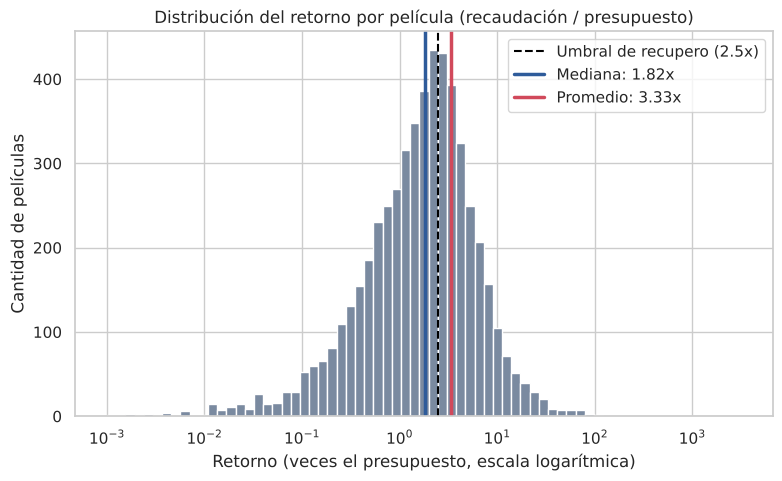

Películas con retorno menor al umbral: 61.3%
Películas por encima del promedio    : 28.3%


In [30]:
figura, eje = plt.subplots(figsize=(9, 5))
bordes = np.logspace(-3, 3.5, 70)
eje.hist(analisis["roi"], bins=bordes, color="#7a8aa0", edgecolor="white")
eje.set_xscale("log")
media_total, mediana_total = analisis["roi"].mean(), analisis["roi"].median()
eje.axvline(
    UMBRAL_RECUPERO, color="black", linestyle="--", label=f"Umbral de recupero ({UMBRAL_RECUPERO}x)"
)
eje.axvline(mediana_total, color="#2e5b9a", linewidth=2.5, label=f"Mediana: {mediana_total:.2f}x")
eje.axvline(media_total, color="#d1495b", linewidth=2.5, label=f"Promedio: {media_total:.2f}x")
eje.set_title("Distribución del retorno por película (recaudación / presupuesto)")
eje.set_xlabel("Retorno (veces el presupuesto, escala logarítmica)")
eje.set_ylabel("Cantidad de películas")
eje.legend()
guardar_figura(figura, "03_distribucion_retorno")
plt.show()
print(f"Películas con retorno menor al umbral: {(analisis['roi'] < UMBRAL_RECUPERO).mean():.1%}")
print(f"Películas por encima del promedio    : {(analisis['roi'] > media_total).mean():.1%}")

**Conclusión.** El promedio (3,33x) es un número que el 72% de las películas no alcanza: solo el 28,3% lo supera. La mediana (1,82x) está por debajo del umbral de recupero, y el 61,3% de las películas no llega a 2,5x.
El promedio lo sostiene una cola derecha de pocas películas con retornos de 50x o más. Decidir con el promedio significaría esperar un rendimiento que casi nadie obtiene.

<h3 style='font-weight:bold; color:#0033BB;'>4.3 Comparación entre géneros, ordenada por valor</h3>

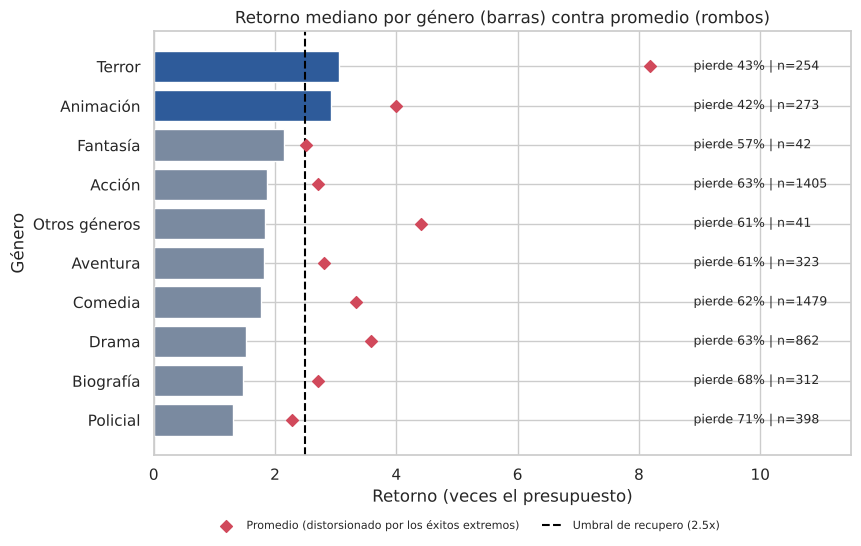

In [31]:
orden = por_genero.sort_values("retorno_mediano")
figura, eje = plt.subplots(figsize=(9, 5.5))
colores = [
    "#2e5b9a" if valor >= UMBRAL_RECUPERO else "#7a8aa0" for valor in orden["retorno_mediano"]
]
eje.barh(orden.index, orden["retorno_mediano"], color=colores)
eje.scatter(
    orden["retorno_medio"],
    orden.index,
    color="#d1495b",
    marker="D",
    zorder=3,
    label="Promedio (distorsionado por los éxitos extremos)",
)
eje.axvline(
    UMBRAL_RECUPERO, color="black", linestyle="--", label=f"Umbral de recupero ({UMBRAL_RECUPERO}x)"
)
for posicion, (_, fila) in enumerate(orden.iterrows()):
    eje.text(
        8.9,
        posicion,
        f"pierde {fila['p_perder']:.0%} | n={int(fila['n'])}",
        va="center",
        fontsize=9,
    )
eje.set_xlim(0, 11.5)
eje.set_title("Retorno mediano por género (barras) contra promedio (rombos)")
eje.set_xlabel("Retorno (veces el presupuesto)")
eje.set_ylabel("Género")
eje.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2, fontsize=8, frameon=False)
guardar_figura(figura, "04_retorno_por_genero")
plt.show()

**Conclusión.** Solo Terror (3,05x) y Animación (2,92x) tienen una mediana por encima del umbral de recupero, y aun así pierden en 43% y 42% de los casos. El resto de los géneros pierde en entre 57% y 71%.
El promedio (rombos) exagera sobre todo a Terror, que casi triplica su mediana: 8,2x contra 3,05x. El orden por mediana y el orden por promedio no coinciden, y el que sirve para decidir es el primero.

<h3 style='font-weight:bold; color:#0033BB;'>4.4 Presupuesto contra recaudación, sin superposición de puntos</h3>

Con más de 5.000 puntos, un gráfico de dispersión se vuelve una mancha. Se agrupan en **celdas hexagonales** coloreadas por cantidad de películas, en escala logarítmica en los dos ejes.

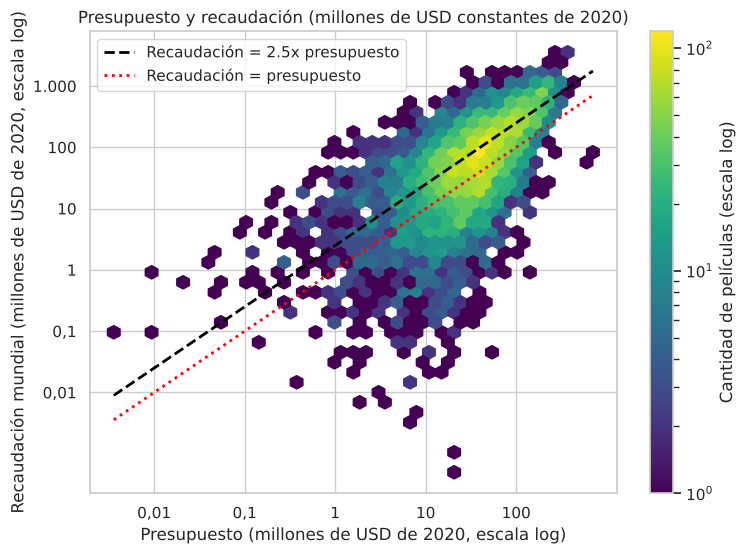

Correlación de Spearman presupuesto-recaudación: 0.66


In [32]:
figura, eje = plt.subplots(figsize=(8.5, 6))
x_log = np.log10(analisis["presupuesto_real"] / 1e6)
y_log = np.log10(analisis["recaudacion_real"] / 1e6)
hexagonos = eje.hexbin(x_log, y_log, gridsize=38, bins="log", cmap="viridis", mincnt=1)
figura.colorbar(hexagonos, ax=eje, label="Cantidad de películas (escala log)")
recta = np.linspace(x_log.min(), x_log.max(), 50)
eje.plot(
    recta,
    recta + np.log10(UMBRAL_RECUPERO),
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Recaudación = {UMBRAL_RECUPERO}x presupuesto",
)
eje.plot(recta, recta, color="red", linestyle=":", linewidth=2, label="Recaudación = presupuesto")
eje.set_xticks([-2, -1, 0, 1, 2], ["0,01", "0,1", "1", "10", "100"])
eje.set_yticks([-2, -1, 0, 1, 2, 3], ["0,01", "0,1", "1", "10", "100", "1.000"])
eje.set_title("Presupuesto y recaudación (millones de USD constantes de 2020)")
eje.set_xlabel("Presupuesto (millones de USD de 2020, escala log)")
eje.set_ylabel("Recaudación mundial (millones de USD de 2020, escala log)")
eje.legend(loc="upper left")
guardar_figura(figura, "05_presupuesto_vs_recaudacion")
plt.show()
print(
    f"Correlación de Spearman presupuesto-recaudación: {analisis['presupuesto_real'].corr(analisis['recaudacion_real'], method='spearman'):.2f}"
)

**Conclusión.** Presupuesto y recaudación están asociados (correlación de Spearman 0,66), pero la mayor parte de las películas se agrupa entre la línea roja (recaudar lo mismo que se gastó) y la línea negra (el 2,5x), o apenas por encima de esta última, y el 61% queda por debajo de la negra:
muchas películas cubren su presupuesto con la boletería y aun así pierden plata según la regla de la industria. Gastar más presupuesto sube la recaudación pero no el múltiplo, y hay películas de todos los tamaños por debajo de la línea.

<h3 style='font-weight:bold; color:#0033BB;'>4.5 Gráfico interactivo (Plotly): el plano de riesgo y retorno</h3>

Cada burbuja es un segmento (género, tramo de presupuesto, clasificación, franquicia, productora, década u origen). **Pasando el mouse** se ve el detalle. La línea une los segmentos no dominados.

In [33]:
frontera = segmentos[segmentos["en_frontera"]].sort_values("p_perder")
figura_plotly = px.scatter(
    segmentos,
    x="p_perder",
    y="retorno_mediano",
    size="n",
    color="familia",
    hover_name="etiqueta",
    hover_data={
        "n": True,
        "p_perder": ":.1%",
        "retorno_mediano": ":.2f",
        "peor_decil": ":.2f",
        "familia": False,
    },
    labels={
        "p_perder": "Probabilidad de perder plata (retorno menor a 2,5x)",
        "retorno_mediano": "Retorno mediano (veces el presupuesto)",
        "familia": "Familia de segmentos",
        "n": "Películas",
        "peor_decil": "Retorno del peor decil",
    },
    title="Riesgo y retorno por segmento: arriba a la izquierda es mejor",
    size_max=34,
    height=620,
)
figura_plotly.add_trace(
    go.Scatter(
        x=frontera["p_perder"],
        y=frontera["retorno_mediano"],
        mode="lines",
        line=dict(color="black", dash="dot"),
        name="Frontera (no dominados)",
        hoverinfo="skip",
    )
)
figura_plotly.add_hline(
    y=UMBRAL_RECUPERO, line_dash="dash", line_color="grey", annotation_text="Umbral 2,5x"
)
figura_plotly.update_xaxes(tickformat=".0%")
figura_plotly.write_html(
    CARPETA_SALIDAS / "06_riesgo_retorno_interactivo.html", include_plotlyjs="cdn"
)
figura_plotly.show()

**Conclusión.** En el plano de riesgo y retorno solo cuatro segmentos forman la frontera. El de menor probabilidad de pérdida entre los grandes es **Franquicia** (41%, con mediana de 2,97x),
y el de mayor mediana (menos de 5 M, 3,34x) es también el más frágil por los datos faltantes. Todo lo que está abajo a la derecha (Policial, década de 1990, Miramax, Castle Rock) ofrece menos retorno con más riesgo.

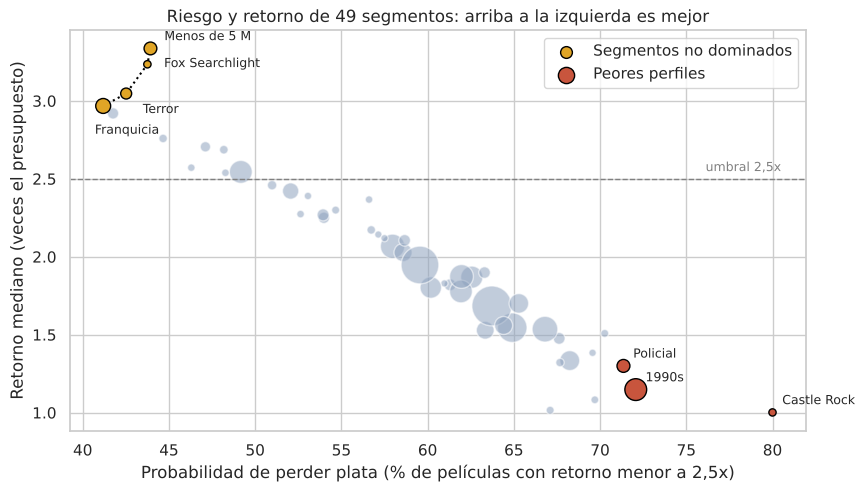

In [34]:
# Versión estática del mismo plano, para la presentación (el gráfico interactivo no entra en una diapositiva)
peores = segmentos.sort_values(["dominado_por", "retorno_mediano"], ascending=[False, True]).head(3)
figura, eje = plt.subplots(figsize=(9.5, 5.2))
eje.scatter(
    segmentos["p_perder"] * 100,
    segmentos["retorno_mediano"],
    s=segmentos["n"] / 6 + 20,
    color="#8fa3bf",
    alpha=0.55,
    edgecolor="white",
)
eje.scatter(
    frontera["p_perder"] * 100,
    frontera["retorno_mediano"],
    s=frontera["n"] / 6 + 20,
    color="#e0a526",
    edgecolor="black",
    zorder=3,
    label="Segmentos no dominados",
)
eje.plot(
    frontera["p_perder"] * 100, frontera["retorno_mediano"], color="black", linestyle=":", zorder=2
)
eje.scatter(
    peores["p_perder"] * 100,
    peores["retorno_mediano"],
    s=peores["n"] / 6 + 20,
    color="#c8553d",
    edgecolor="black",
    zorder=3,
    label="Peores perfiles",
)
# Desplazamientos manuales (en puntos) para que las etiquetas de la esquina superior no se pisen
DESPLAZAMIENTO_ETIQUETAS = {
    "Menos de 5 M": (10, 6),
    "Fox Searchlight": (12, -2),
    "Terror": (12, -14),
    "Franquicia": (-6, -20),
}
for _, fila in pd.concat([frontera, peores]).iterrows():
    nombre = fila["etiqueta"].split(": ")[1].replace(" Pictures", "").replace(" Entertainment", "")
    desplazamiento = DESPLAZAMIENTO_ETIQUETAS.get(nombre, (7, 6))
    eje.annotate(
        nombre,
        (fila["p_perder"] * 100, fila["retorno_mediano"]),
        textcoords="offset points",
        xytext=desplazamiento,
        fontsize=9,
    )
eje.axhline(UMBRAL_RECUPERO, color="grey", linestyle="--", linewidth=1)
eje.text(80.5, UMBRAL_RECUPERO + 0.05, "umbral 2,5x", color="grey", fontsize=9, ha="right")
eje.set_title("Riesgo y retorno de 49 segmentos: arriba a la izquierda es mejor")
eje.set_xlabel("Probabilidad de perder plata (% de películas con retorno menor a 2,5x)")
eje.set_ylabel("Retorno mediano (veces el presupuesto)")
eje.legend(loc="upper right")
guardar_figura(figura, "08_plano_riesgo_retorno")
plt.show()

<h2 style='font-weight:bold; color:#003366;'>Etapa 5: La tesis de inversión</h2>

<h3 style='font-weight:bold; color:#0033BB;'>5.1 Los grupos de películas (arquetipos)</h3>

Se definen **cinco grupos** con criterios que se pueden verificar en los datos (género, franquicia, presupuesto en dólares constantes).
Se aplican **en orden de prioridad** (una película cae en el primero que cumple), de modo que los grupos no se superponen.
Los umbrales son redondos a propósito (50, 30 y 80 millones) para no ajustarlos al dato. Las métricas que justifican cada grupo y la cantidad de proyectos se calculan **solo con películas hasta 2014**. Una advertencia de honestidad: la sección 3 exploró toda la muestra, así que la prueba de la sección 5.5 es una verificación de estabilidad y no una prueba completamente ciega.

In [35]:
ARQUETIPOS = [
    "A. Franquicia grande",
    "B. Animación",
    "C. Terror contenido",
    "D. Acción o aventura grande sin franquicia",
    "E. Resto del mercado",
]
GENEROS_TENTPOLE = ["Acción", "Aventura", "Fantasía", "Ciencia ficción"]
PRESUPUESTO_FRANQUICIA_GRANDE = 50e6  # USD de 2020
PRESUPUESTO_TERROR_MAXIMO = 30e6
PRESUPUESTO_TENTPOLE_MINIMO = 80e6


def asignar_arquetipo(df):
    """Asigna cada película al primer arquetipo cuyo criterio cumple (orden de prioridad)."""
    condiciones = [
        df["es_secuela"] & (df["presupuesto_real"] >= PRESUPUESTO_FRANQUICIA_GRANDE),
        df["genero"] == "Animación",
        (df["genero"] == "Terror") & (df["presupuesto_real"] < PRESUPUESTO_TERROR_MAXIMO),
        df["genero"].isin(GENEROS_TENTPOLE)
        & (df["presupuesto_real"] >= PRESUPUESTO_TENTPOLE_MINIMO),
    ]
    return np.select(condiciones, ARQUETIPOS[:4], default=ARQUETIPOS[4])


analisis["arquetipo"] = asignar_arquetipo(analisis)
entrenamiento = analisis[analisis["anio_estreno"] <= ANIO_CORTE].copy()
prueba = analisis[analisis["anio_estreno"] > ANIO_CORTE].copy()
print(
    f"Películas de entrenamiento (hasta {ANIO_CORTE}): {len(entrenamiento):,} | de prueba (2015-2020): {len(prueba):,}"
)


def tabla_arquetipos(df):
    """Métricas de riesgo y retorno por arquetipo."""
    tabla = metricas_segmento(df, "arquetipo").reindex(ARQUETIPOS)
    tabla["presupuesto_tipico_M"] = (
        df.groupby("arquetipo")["presupuesto_real"].median().reindex(ARQUETIPOS) / 1e6
    )
    return tabla[
        [
            "n",
            "retorno_medio",
            "retorno_mediano",
            "p_perder",
            "peor_decil",
            "retorno_mediano_ajustado",
            "p_perder_ajustada",
            "presupuesto_tipico_M",
        ]
    ]


tabla_entrenamiento = tabla_arquetipos(entrenamiento)
print("ENTRENAMIENTO (hasta 2014). Los criterios y la asignación salen de esta tabla:")
display(tabla_entrenamiento)

Películas de entrenamiento (hasta 2014): 4,683 | de prueba (2015-2020): 706
ENTRENAMIENTO (hasta 2014). Los criterios y la asignación salen de esta tabla:


,n,retorno_medio,retorno_mediano,p_perder,peor_decil,retorno_mediano_ajustado,p_perder_ajustada,presupuesto_tipico_M
segmento,,,,,,,,
A. Franquicia grande,226,3.77,2.92,0.41,0.92,2.86,0.44,102.50
B. Animación,183,3.73,2.76,0.48,0.49,2.21,0.54,68.50
C. Terror contenido,177,9.16,3.14,0.40,0.36,2.51,0.50,10.82
D. Acción o aventura grande sin franquicia,374,2.37,1.96,0.63,0.51,1.86,0.65,120.75
E. Resto del mercado,3723,2.93,1.51,0.67,0.21,1.05,0.73,29.15


**Lectura (solo entrenamiento, hasta 2014).** Tres grupos se separan del resto:

- **A. Franquicia grande** (secuelas de 50 M o más): mediana 2,92x, pierde en 41%, el mejor peor decil (0,92x: el 90% de estas películas recauda al menos 0,92 veces lo que costó). Presupuesto típico USD 102,5 M.
- **B. Animación**: mediana 2,76x, pierde en 48%, presupuesto típico 68,5 M.
- **C. Terror contenido** (menos de 30 M): mediana 3,14x, pierde en 40%, presupuesto típico 10,8 M, pero con el peor decil bajo (0,36x).

Contra eso, **D. Acción o aventura grande sin franquicia** (1,96x, pierde 63%, presupuesto típico 120,8 M) y **E. el resto** (1,51x, pierde 67%) no llegan al umbral. Ajustando por faltantes, las medianas son 2,86x, 2,21x y 2,51x para A, B y C, y 1,86x y 1,05x para D y E:
el orden se mantiene.

Un dato incómodo: incluso en los mejores grupos, entre 40% y 54% de las películas individuales **no recuperan**. Un proyecto aislado es casi una moneda al aire; lo que tiene valor es el portafolio.

**¿Los arquetipos dependen de pocos éxitos extremos o de un par de décadas?** Dos controles antes de confiar en ellos.

In [36]:
concentracion_arq = (
    entrenamiento.groupby("arquetipo")
    .apply(concentracion_top, include_groups=False)
    .reindex(ARQUETIPOS)
)
estabilidad = (
    entrenamiento.groupby(["arquetipo", "decada"])["roi"].median().unstack().reindex(ARQUETIPOS)
)
control = pd.DataFrame(
    {
        "fraccion_retorno_en_top5": concentracion_arq,
        "mejor_decada_sobre_peor": estabilidad.max(axis=1) / estabilidad.min(axis=1),
    }
)
display(control)
print("Retorno mediano por década (¿es estable o vive de una época?):")
display(estabilidad[["1980s", "1990s", "2000s", "2010s"]])

,fraccion_retorno_en_top5,mejor_decada_sobre_peor
arquetipo,,
A. Franquicia grande,0.10,1.53
B. Animación,0.18,1.81
C. Terror contenido,0.26,4.19
D. Acción o aventura grande sin franquicia,0.07,2.93
E. Resto del mercado,0.03,2.21


Retorno mediano por década (¿es estable o vive de una época?):


decada,1980s,1990s,2000s,2010s
arquetipo,,,,
A. Franquicia grande,3.00,2.43,2.66,3.71
B. Animación,2.58,1.64,2.40,2.96
C. Terror contenido,3.31,2.00,3.21,8.38
D. Acción o aventura grande sin franquicia,0.77,1.95,1.87,2.27
E. Resto del mercado,1.48,1.00,1.66,2.21


**Lectura.** Franquicias es el grupo más estable: su mejor década es solo 1,5 veces su peor (retorno mediano entre 2,43x y 3,71x), y las 5 mejores películas explican apenas el 10% del retorno total.
Terror contenido es el opuesto: la mejor década es **4,2 veces** la peor (2,00x en los 90 contra 8,38x en los 2010) y el 26% del retorno total lo explican 5 películas. Su resultado depende de una época y de unos pocos éxitos.
Animación tiene una amplitud intermedia (1,8 veces). Esto condiciona cuánto se puede apostar a cada grupo.

<h3 style='font-weight:bold; color:#0033BB;'>5.2 Asignación de los USD 500 millones</h3>

La cantidad de proyectos sale de dividir el capital de cada grupo por su **presupuesto típico** (mediana en dólares de 2020 de las películas de entrenamiento).
Es la verificación de coherencia que pide la letra: si el grupo tiene presupuesto típico de 100 M, no se pueden hacer 10 proyectos con 100 M.
Se reserva el 10% del fondo para sobrecostos y desarrollo (no es retorno: es colchón, y si no se usa vuelve al fondo).

In [37]:
PROYECTOS_ELEGIDOS = {"A. Franquicia grande": 2, "B. Animación": 2, "C. Terror contenido": 10}

presupuesto_tipico = entrenamiento.groupby("arquetipo")["presupuesto_real"].median()
rango_p25 = entrenamiento.groupby("arquetipo")["presupuesto_real"].quantile(0.25)
rango_p75 = entrenamiento.groupby("arquetipo")["presupuesto_real"].quantile(0.75)

asignacion = pd.DataFrame(
    {
        "proyectos": pd.Series(PROYECTOS_ELEGIDOS),
        "presupuesto_tipico_M": presupuesto_tipico.reindex(list(PROYECTOS_ELEGIDOS)) / 1e6,
        "rango_p25_p75_M": pd.Series(
            {a: f"{rango_p25[a] / 1e6:.0f} a {rango_p75[a] / 1e6:.0f}" for a in PROYECTOS_ELEGIDOS}
        ),
    }
)
asignacion["capital_M"] = asignacion["proyectos"] * asignacion["presupuesto_tipico_M"]
asignacion["pct_del_fondo"] = asignacion["capital_M"] / (PRESUPUESTO_FONDO / 1e6) * 100
capital_invertido = asignacion["capital_M"].sum()
reserva = PRESUPUESTO_FONDO / 1e6 - capital_invertido
display(asignacion)
print(
    f"Capital asignado a proyectos: USD {capital_invertido:,.0f} M ({capital_invertido / (PRESUPUESTO_FONDO / 1e6):.0%}) | reserva: USD {reserva:,.0f} M"
)
print(
    f"Proyectos totales: {int(asignacion['proyectos'].sum())} en tres años (unos {asignacion['proyectos'].sum() / 3:.1f} por año)"
)
asignacion.to_csv(CARPETA_SALIDAS / "asignacion_fondo.csv")

,proyectos,presupuesto_tipico_M,rango_p25_p75_M,capital_M,pct_del_fondo
A. Franquicia grande,2,102.50,70 a 165,204.99,41.00
B. Animación,2,68.50,36 a 135,137.00,27.40
C. Terror contenido,10,10.82,5 a 19,108.18,21.64


Capital asignado a proyectos: USD 450 M (90%) | reserva: USD 50 M
Proyectos totales: 14 en tres años (unos 4.7 por año)


**Lectura.** La asignación propuesta es de **14 proyectos** (unos 4,7 por año):

- **2 franquicias grandes** por USD 205 M (41% del fondo). Presupuesto típico 102,5 M y rango intercuartil de 70 a 165 M.
- **2 animaciones** por USD 137 M (27,4%). Típico 68,5 M, rango de 36 a 135 M.
- **10 películas de terror contenido** por USD 108 M (21,6%). Típico 10,8 M, rango de 5 a 19 M.
- **Reserva de USD 50 M (10%)** para sobrecostos y desarrollo.

La cantidad de proyectos es coherente con el presupuesto típico de cada grupo: se compran pocas películas caras y varias baratas, no al revés. El costo es que las franquicias y la animación son **piezas grandes** (con solo 2 proyectos de cada una, un fracaso pesa mucho),
y que la franquicia exige acceso a los derechos (la tesis supone coinversión con un estudio dueño de la propiedad).

<h3 style='font-weight:bold; color:#0033BB;'>5.3 Retorno esperado y probabilidad de perder capital: simulación</h3>

No se usa el promedio: se **simula**. En cada una de las 20.000 repeticiones se arma un portafolio sacando, con reposición, películas reales del grupo
correspondiente (tantas como proyectos) y se calcula el retorno del portafolio completo: recaudación total dividida por capital invertido. De las 20.000 repeticiones salen la mediana, el peor 5% y la
**probabilidad de que el portafolio no llegue al umbral de recupero** (2,5×; y también al estricto de 3,5×, que descuenta la parte del exhibidor y el marketing).

Hay tres versiones del mismo portafolio, para ver cuánto depende la respuesta de supuestos discutibles:

- **Observado**: las películas con presupuesto conocido, tal cual.
- **Ajustado**: las mismas, con los ponderadores por faltantes de la sección 1.9 (escenario conservador).
- **Sin los 3 mayores éxitos** de cada grupo: qué pasa si los golpes de suerte no se repiten.
- **Década adversa**: todos los proyectos salen con los retornos de los años 90, la peor época de la base. Es una prueba de estrés por correlación: el sorteo independiente supone que las películas no se mueven juntas, y en la realidad el mercado tiene épocas buenas y malas.

In [38]:
def armar_pools(df, ajustado=False, quitar_top=0, decada=None):
    """Por arquetipo: retornos históricos y su probabilidad de ser elegidos (uniforme o ajustada).

    `quitar_top` descarta los mayores éxitos de cada arquetipo; `decada` limita el pool a una época.
    """
    if decada is not None:
        df = df[df["decada"] == decada]
    pools = {}
    for arquetipo in ARQUETIPOS:
        grupo = (
            df[df["arquetipo"] == arquetipo].sort_values("roi", ascending=False).iloc[quitar_top:]
        )
        pesos = grupo["peso_faltantes"] if ajustado else pd.Series(1.0, index=grupo.index)
        pools[arquetipo] = (grupo["roi"].to_numpy(), (pesos / pesos.sum()).to_numpy())
    return pools


def simular(proyectos, pools, n_simulaciones=N_SIMULACIONES, semilla=SEMILLA):
    """Simula portafolios. `proyectos` = {arquetipo: (cantidad, presupuesto_unitario)}.

    Devuelve el retorno de cada portafolio simulado: recaudación total / capital invertido.
    """
    generador = np.random.default_rng(semilla)
    invertido = sum(cantidad * presupuesto for cantidad, presupuesto in proyectos.values())
    recaudado = np.zeros(n_simulaciones)
    for arquetipo, (cantidad, presupuesto) in proyectos.items():
        retornos, probabilidades = pools[arquetipo]
        sorteo = generador.choice(retornos, size=(n_simulaciones, cantidad), p=probabilidades)
        recaudado += sorteo.sum(axis=1) * presupuesto
    return recaudado / invertido


def margen_neto(multiplo):
    """Margen estimado sobre el costo total (producción + marketing) para un retorno bruto dado.

    El estudio se queda con PARTE_ESTUDIO de la boletería y gasta (1 + marketing) veces el presupuesto.
    """
    costo_total = 1 + MARKETING_SOBRE_PRESUPUESTO
    return (PARTE_ESTUDIO * multiplo - costo_total) / costo_total


def resumir(multiplos):
    """Estadísticos de un conjunto de retornos de portafolio simulados."""
    peor_5 = np.percentile(multiplos, 5)
    return {
        "retorno_mediano": np.median(multiplos),
        "margen_neto_mediano": margen_neto(np.median(multiplos)),
        "peor_5pct": peor_5,
        "faltante_peor_5pct_vs_2_5x": max(0.0, 1 - peor_5 / UMBRAL_RECUPERO),
        "p_menor_2_5x": (multiplos < UMBRAL_RECUPERO).mean(),
        "p_menor_3_5x": (multiplos < UMBRAL_ESTRICTO).mean(),
        "p_menor_1x": (multiplos < 1).mean(),
    }


proyectos_elegidos = {a: (n, presupuesto_tipico[a]) for a, n in PROYECTOS_ELEGIDOS.items()}

escenarios_entrenamiento = {
    "Observado": armar_pools(entrenamiento),
    "Ajustado por faltantes": armar_pools(entrenamiento, ajustado=True),
    "Sin los 3 mayores éxitos": armar_pools(entrenamiento, quitar_top=3),
    "Década adversa (solo años 90)": armar_pools(entrenamiento, decada="1990s"),
}
simulaciones_elegido = {
    nombre: simular(proyectos_elegidos, pools) for nombre, pools in escenarios_entrenamiento.items()
}
resumen_elegido = pd.DataFrame({nombre: resumir(m) for nombre, m in simulaciones_elegido.items()}).T
display(resumen_elegido)

,retorno_mediano,margen_neto_mediano,peor_5pct,faltante_peor_5pct_vs_2_5x,p_menor_2_5x,p_menor_3_5x,p_menor_1x
Observado,4.74,0.35,2.59,0.00,0.04,0.21,0.00
Ajustado por faltantes,4.16,0.19,2.14,0.14,0.10,0.33,0.00
Sin los 3 mayores éxitos,4.33,0.24,2.48,0.01,0.05,0.26,0.00
Década adversa (solo años 90),3.01,-0.14,1.41,0.43,0.35,0.62,0.01


**Lectura (portafolio propuesto, películas hasta 2014).**

- **Retorno esperado.** La mediana del portafolio es **4,16x** el capital invertido en el escenario ajustado (4,74x observado). Con el criterio estricto (50% para el exhibidor y 75% de marketing) eso equivale a un margen neto mediano de **+19%** sobre el costo total.
- **Probabilidad de perder capital.** La probabilidad de no llegar al 2,5x es **10%** en el escenario ajustado (4% observado, 5% sin los 3 mayores éxitos). Contra el 3,5x estricto, la probabilidad sube a 33%.
- **Cuánto se puede perder.** En el peor 5% de los casos el portafolio llega a 2,14x, o sea 14% por debajo del punto de equilibrio de la industria.
- **Prueba de estrés.** Si todas las películas salen con los retornos de los años 90, la peor época, la mediana baja a 3,01x, la probabilidad de no llegar al 2,5x sube a **35%** y el margen neto mediano pasa a **-14%**.

La respuesta al comité tiene que incluir los dos números: 10% en condiciones como las de la muestra y 35% si el mercado se parece a los años 90. La probabilidad de que la boletería no cubra ni el presupuesto (retorno menor a 1x) es del 1% o menos en todos los escenarios, pero se puede perder plata igual por la parte del exhibidor y por el marketing.

<h3 style='font-weight:bold; color:#0033BB;'>5.4 ¿Por qué no poner todo en el segmento de mejor retorno?</h3>

In [39]:
def proyectos_para(arquetipo, capital=PRESUPUESTO_FONDO):
    """Cuántos proyectos de presupuesto típico entran con `capital` en un solo arquetipo."""
    return {
        arquetipo: (int(capital // presupuesto_tipico[arquetipo]), presupuesto_tipico[arquetipo])
    }


mercado_tipico = entrenamiento["presupuesto_real"].median()
estrategias = {
    "Propuesta (A+B+C, 14 proyectos)": proyectos_elegidos,
    "Todo en terror contenido": proyectos_para("C. Terror contenido"),
    "Todo en franquicias grandes": proyectos_para("A. Franquicia grande"),
    "Todo en animación": proyectos_para("B. Animación"),
    "Todo en acción o aventura grande": proyectos_para(
        "D. Acción o aventura grande sin franquicia"
    ),
    "Mercado: películas elegidas al azar": {
        "E. Resto del mercado": (int(PRESUPUESTO_FONDO // mercado_tipico), mercado_tipico)
    },
}


def pool_mercado(df, **opciones):
    """Pool de 'mercado al azar': todas las películas del período como si fueran un solo grupo."""
    todo = df.assign(arquetipo="E. Resto del mercado")
    return {"E. Resto del mercado": armar_pools(todo, **opciones)["E. Resto del mercado"]}


filas = []
for nombre, proyectos in estrategias.items():
    es_mercado = nombre.startswith("Mercado")
    pools_ajustado = (
        pool_mercado(entrenamiento, ajustado=True)
        if es_mercado
        else escenarios_entrenamiento["Ajustado por faltantes"]
    )
    pools_sin_top = (
        pool_mercado(entrenamiento, quitar_top=3)
        if es_mercado
        else escenarios_entrenamiento["Sin los 3 mayores éxitos"]
    )
    pools_adverso = (
        pool_mercado(entrenamiento, decada="1990s")
        if es_mercado
        else escenarios_entrenamiento["Década adversa (solo años 90)"]
    )
    ajustado = simular(proyectos, pools_ajustado)
    sin_top = simular(proyectos, pools_sin_top)
    adverso = simular(proyectos, pools_adverso)
    filas.append(
        {
            "estrategia": nombre,
            "proyectos": sum(n for n, _ in proyectos.values()),
            "mediana_ajustada": np.median(ajustado),
            "p_perder_ajustada": (ajustado < UMBRAL_RECUPERO).mean(),
            "p_perder_sin_top3": (sin_top < UMBRAL_RECUPERO).mean(),
            "mediana_decada_adversa": np.median(adverso),
            "p_perder_decada_adversa": (adverso < UMBRAL_RECUPERO).mean(),
        }
    )
comparacion_estrategias = pd.DataFrame(filas).set_index("estrategia")
display(comparacion_estrategias)

peliculas_terror = int((entrenamiento["arquetipo"] == "C. Terror contenido").sum())
anios_entrenamiento = ANIO_CORTE - 1980 + 1
print(
    f"Terror contenido: {peliculas_terror} películas con presupuesto conocido en {anios_entrenamiento} años (unas {peliculas_terror / anios_entrenamiento:.1f} por año en esta base)."
)
print(
    f"'Todo en terror' exigiría {proyectos_para('C. Terror contenido')['C. Terror contenido'][0]} proyectos."
)

,proyectos,mediana_ajustada,p_perder_ajustada,p_perder_sin_top3,mediana_decada_adversa,p_perder_decada_adversa
estrategia,,,,,,
"Propuesta (A+B+C, 14 proyectos)",14,4.16,0.10,0.05,3.01,0.35
Todo en terror contenido,46,7.27,0.00,0.00,3.21,0.14
Todo en franquicias grandes,4,3.31,0.25,0.22,2.96,0.38
Todo en animación,7,2.99,0.34,0.24,3.31,0.37
Todo en acción o aventura grande,4,2.13,0.66,0.65,2.19,0.63
Mercado: películas elegidas al azar,14,2.32,0.57,0.40,2.21,0.61


Terror contenido: 177 películas con presupuesto conocido en 35 años (unas 5.1 por año en esta base).
'Todo en terror' exigiría 46 proyectos.


**Lectura.** Sobre el papel, "todo en terror contenido" gana: mediana 7,27x y 0% de probabilidad de pérdida en el escenario ajustado, y aun así 14% en la década adversa. La simulación sola recomendaría cargar el portafolio con terror.
La tesis **no lo hace**, por cuatro razones que la simulación no ve:

1. **Capacidad.** Haría falta financiar 46 proyectos. En la base hay 5,1 películas de terror contenido por año, o sea unas 15 en tres años: se necesitarían tres veces todo el volumen de la base. Incluso los 10 proyectos propuestos son una porción grande y habrá que validar que existan.
2. **Dependencia de una época y de pocos éxitos.** La mejor década es 4,2 veces la peor y 5 películas explican el 26% del retorno. La simulación sortea las películas en forma independiente, y en la realidad el éxito del terror se mueve junto (modas, plataformas, distribuidores).
3. **Es el grupo con la estimación menos confiable.** Su mediana cae de 3,14x a 2,51x al corregir por faltantes, en la prueba tiene solo 30 películas, y la base contiene solo películas que llegaron a estrenarse: los terrores baratos que nunca tuvieron distribución no están en los datos.
4. **Concentración de mecanismo.** Todo el fondo dependería de una sola hipótesis.

Los demás extremos son peores: todo en franquicias (4 proyectos, pierde 25%), todo en animación (7 proyectos, 34%), todo en acción o aventura grande (66%), o elegir películas al azar del mercado (57% de pérdida, 61% en la década adversa).
La propuesta (10% de pérdida, 35% en la década adversa) combina tres mecanismos distintos y renuncia a parte de la mediana a cambio de no depender de una sola apuesta.

<h3 style='font-weight:bold; color:#0033BB;'>5.5 ¿La tesis sobrevive fuera de muestra? (2015-2020)</h3>

Los criterios (arquetipos, presupuestos típicos, cantidad de proyectos) se construyeron **solo con películas hasta 2014**. Ahora se aplican, sin tocar nada,
a las 706 películas estrenadas entre 2015 y 2020 y se compara lo que la tesis esperaba con lo que pasó.

entrenamiento                  \
                                                       n retorno_mediano   
segmento                                                                   
A. Franquicia grande                                 226            2.92   
B. Animación                                         183            2.76   
C. Terror contenido                                  177            3.14   
D. Acción o aventura grande sin franquicia           374            1.96   
E. Resto del mercado                                3723            1.51   

                                                               prueba  \
                                           p_perder peor_decil      n   
segmento                                                                
A. Franquicia grande                           0.41       0.92     74   
B. Animación                                   0.48       0.49     45   
C. Terror contenido                            0.40       0.36     30   
D. Acción o aventura grande sin franquicia     0.63       0.51     81   
E. Resto del mercado                           0.67       0.21    476   

                                                                                
                                           retorno_mediano p_perder peor_decil  
segmento                                                                        
A. Franquicia grande                                  3.84     0.23       1.86  
B. Animación                                          3.30     0.33       0.71  
C. Terror contenido                                   6.80     0.23       0.56  
D. Acción o aventura grande sin franquicia            2.31     0.53       1.04  
E. Resto del mercado                                  2.33     0.53       0.42

Portafolio propuesto, simulado con películas 2015-2020:


,retorno_mediano,margen_neto_mediano,peor_5pct,faltante_peor_5pct_vs_2_5x,p_menor_2_5x,p_menor_3_5x,p_menor_1x
Observado,5.79,0.65,3.80,0.00,0.00,0.03,0.00
Ajustado por faltantes,4.99,0.43,3.09,0.00,0.01,0.11,0.00
Sin los 3 mayores éxitos,4.78,0.37,3.33,0.00,0.00,0.08,0.00


Mercado elegido al azar en 2015-2020 (ajustado): mediana 3.50x, probabilidad de perder 16.9%


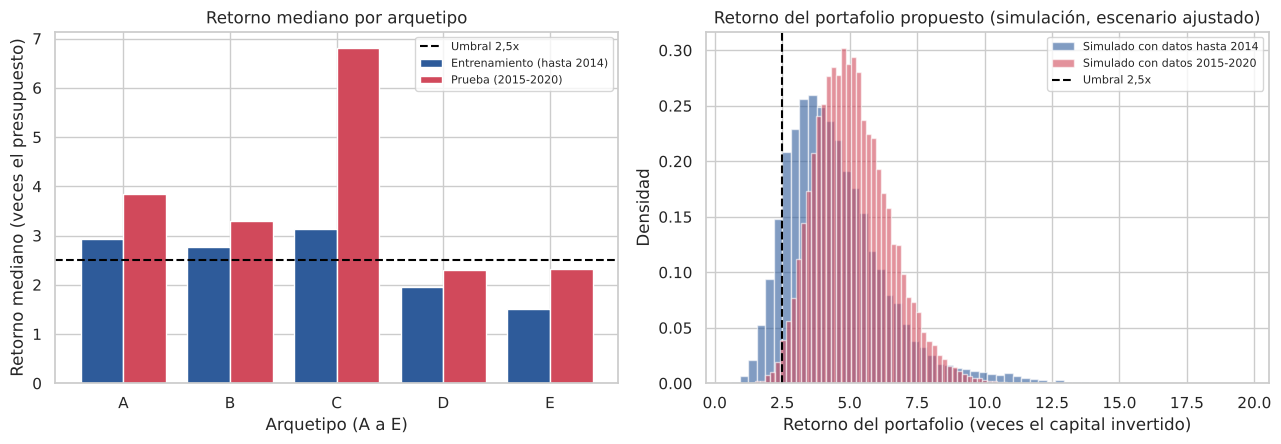

In [40]:
tabla_prueba = tabla_arquetipos(prueba)
comparacion_periodos = pd.concat(
    {
        "entrenamiento": tabla_entrenamiento[["n", "retorno_mediano", "p_perder", "peor_decil"]],
        "prueba": tabla_prueba[["n", "retorno_mediano", "p_perder", "peor_decil"]],
    },
    axis=1,
)
display(comparacion_periodos)

# Simulación del MISMO portafolio con las películas de 2015-2020
escenarios_prueba = {
    "Observado": armar_pools(prueba),
    "Ajustado por faltantes": armar_pools(prueba, ajustado=True),
    "Sin los 3 mayores éxitos": armar_pools(prueba, quitar_top=3),
}
simulaciones_prueba = {
    nombre: simular(proyectos_elegidos, pools) for nombre, pools in escenarios_prueba.items()
}
resumen_prueba = pd.DataFrame({nombre: resumir(m) for nombre, m in simulaciones_prueba.items()}).T
print("Portafolio propuesto, simulado con películas 2015-2020:")
display(resumen_prueba)

# Mercado al azar en la misma ventana de prueba (referencia)
mercado_prueba = {
    "E. Resto del mercado": (int(PRESUPUESTO_FONDO // mercado_tipico), mercado_tipico)
}
sim_mercado_prueba = simular(mercado_prueba, pool_mercado(prueba, ajustado=True))
print(
    f"Mercado elegido al azar en 2015-2020 (ajustado): mediana {np.median(sim_mercado_prueba):.2f}x, probabilidad de perder {(sim_mercado_prueba < UMBRAL_RECUPERO).mean():.1%}"
)

figura, ejes = plt.subplots(1, 2, figsize=(13, 4.6))
posiciones = np.arange(len(ARQUETIPOS))
ejes[0].bar(
    posiciones - 0.2,
    tabla_entrenamiento["retorno_mediano"],
    0.4,
    label="Entrenamiento (hasta 2014)",
    color="#2e5b9a",
)
ejes[0].bar(
    posiciones + 0.2,
    tabla_prueba["retorno_mediano"],
    0.4,
    label="Prueba (2015-2020)",
    color="#d1495b",
)
ejes[0].axhline(UMBRAL_RECUPERO, color="black", linestyle="--", label="Umbral 2,5x")
ejes[0].set_xticks(posiciones, [a.split(".")[0] for a in ARQUETIPOS])
ejes[0].set_title("Retorno mediano por arquetipo")
ejes[0].set_xlabel("Arquetipo (A a E)")
ejes[0].set_ylabel("Retorno mediano (veces el presupuesto)")
ejes[0].legend(fontsize=8)
ejes[1].hist(
    simulaciones_elegido["Ajustado por faltantes"],
    bins=60,
    alpha=0.6,
    color="#2e5b9a",
    label="Simulado con datos hasta 2014",
    density=True,
)
ejes[1].hist(
    simulaciones_prueba["Ajustado por faltantes"],
    bins=60,
    alpha=0.6,
    color="#d1495b",
    label="Simulado con datos 2015-2020",
    density=True,
)
ejes[1].axvline(UMBRAL_RECUPERO, color="black", linestyle="--", label="Umbral 2,5x")
ejes[1].set_title("Retorno del portafolio propuesto (simulación, escenario ajustado)")
ejes[1].set_xlabel("Retorno del portafolio (veces el capital invertido)")
ejes[1].set_ylabel("Densidad")
ejes[1].legend(fontsize=8)
plt.tight_layout()
guardar_figura(figura, "07_fuera_de_muestra")
plt.show()

**Lectura.** Con los criterios construidos hasta 2014, el orden se sostiene en 2015-2020: los tres arquetipos elegidos siguen mejor que el resto.

| Arquetipo | Mediana 2014- | Mediana 2015-20 | Pierde 2014- | Pierde 2015-20 |
|---|---|---|---|---|
| A. Franquicia grande | 2,92x | 3,84x | 41% | 23% |
| B. Animación | 2,76x | 3,30x | 48% | 33% |
| C. Terror contenido | 3,14x | 6,80x | 40% | 23% |
| D. Acción o aventura grande | 1,96x | 2,31x | 63% | 53% |
| E. Resto | 1,51x | 2,33x | 67% | 53% |

El portafolio propuesto simulado con películas de 2015-2020 tiene una mediana de 4,99x (ajustado) y una probabilidad de no llegar al 2,5x de **1%** (contra el 10% estimado con los datos de entrenamiento); contra el 3,5x estricto la probabilidad es 11%.
Mercado al azar en ese período: mediana 3,50x y 16,9% de probabilidad de pérdida.

**Qué sobrevive y qué no.** Sobrevive el **orden**: A, B y C pierden menos y rinden más que D y E. No sobreviven los **niveles**: en 2015-2020 todos los grupos mejoraron, incluso el resto del mercado (de 1,51x a 2,33x),
así que la ventaja relativa de la tesis sobre el mercado se achicó (1% contra 17% de pérdida, frente a 10% contra 57% en el entrenamiento). La estimación de riesgo de entrenamiento (10%) resultó conservadora para este período, pero conviene planificar con el escenario adverso (35%).
Advertencia de tamaño: en la prueba hay 74, 45 y 30 películas en los arquetipos A, B y C, y 2020 aporta solo 25 películas.

<h3 style='font-weight:bold; color:#0033BB;'>5.6 En qué no invertiríamos y limitaciones</h3>

### En qué no invertiríamos

- **D. Acción o aventura grande sin franquicia.** Es el grupo con los cheques más grandes (típico 120,8 M) y mal perfil: mediana 1,96x, pierde en 63% y en la prueba pasa a 2,31x con 53% de pérdida. Mucho capital por proyecto, sin retorno que lo justifique.
- **E. Drama, comedia, policial, biografía y el resto**: 3.723 películas con mediana de 1,51x, 67% de pérdida y un peor decil de 0,21x. El género Policial es el peor de todos (1,30x, 71%).
- **Películas de menos de 5 M como estrategia general.** Tienen la mediana más alta de todos los segmentos (3,34x), pero es el tramo con más presupuestos faltantes y bajo el ajuste cae a 2,06x. Solo entran en la tesis como parte del terror contenido.
- **Películas sin clasificar o con clasificación *Mayores de 17* sin otro criterio** (1,02x y 1,55x de mediana).

### Limitaciones del análisis

1. **Solo hay películas estrenadas.** La base no contiene proyectos que nunca llegaron a las salas: el retorno de las películas baratas está sobreestimado por supervivencia.
2. **28,9% de las películas no tiene presupuesto y esos faltantes no son aleatorios.** La corrección por ponderación supone que, dada la recaudación y el origen, el presupuesto faltante se parece al observado: no se puede verificar.
3. **Solo boletería.** No hay ingresos de streaming, televisión o venta digital, que hoy pueden ser una parte grande del negocio. Y el 2,5x y el 3,5x son reglas generales, no el flujo de fondos de cada proyecto.
4. **Los sorteos son independientes.** Una cartera real tiene correlación (modas, ventanas de estreno, un mal año). La prueba con la década de 1990 intenta acotar ese problema pero no lo elimina.
5. **Acceso a franquicias.** El fondo no puede crear una secuela: necesita derechos o un socio. Y las franquicias existen porque la película anterior funcionó.
6. **Corrección de escala.** La regla de los 48 presupuestos en miles es razonable pero no infalible (ver *Paranormal Activity*), y puede haber errores de escala que no activen la regla.
7. **Muestras chicas en la prueba** (30 a 81 películas en los arquetipos A a D) y una base que representa unas 200 películas por año, no toda la industria.
8. **Dólares de 2020.** El IPC provisto termina en 2020: los presupuestos típicos deberían actualizarse por la inflación posterior antes de fijar montos.
9. **Los grupos se definieron con la muestra completa a la vista** (sección 3), por lo que la prueba de 2015-2020 es una verificación de estabilidad y no una validación completamente ciega.

<h2 style='font-weight:bold; color:#003366;'>Cierre: cifras clave y trazabilidad</h2>

Todos los números de la presentación salen de esta celda o de las celdas indicadas.

In [41]:
cifras = {
    "Películas en la base cruda": (BASE_INICIAL, "1.2"),
    "Películas en la base limpia": (len(peliculas), "1.3"),
    "Películas con retorno calculable": (len(analisis), "2.3"),
    "% sin presupuesto (con centinelas)": (f"{peliculas['sin_presupuesto'].mean():.1%}", "1.9"),
    "Retorno medio de la industria": (f"{analisis['roi'].mean():.2f}x", "3.2"),
    "Retorno mediano de la industria": (f"{analisis['roi'].median():.2f}x", "3.2"),
    "% de películas que NO recupera (2,5x)": (f"{analisis['no_recupera'].mean():.1%}", "3.3"),
    "Portafolio: retorno mediano (ajustado, entrenamiento)": (
        f"{resumen_elegido.loc['Ajustado por faltantes', 'retorno_mediano']:.2f}x",
        "5.3",
    ),
    "Portafolio: P(no llegar a 2,5x) ajustada, entrenamiento": (
        f"{resumen_elegido.loc['Ajustado por faltantes', 'p_menor_2_5x']:.1%}",
        "5.3",
    ),
    "Portafolio: P(no llegar a 2,5x) ajustada, prueba 2015-2020": (
        f"{resumen_prueba.loc['Ajustado por faltantes', 'p_menor_2_5x']:.1%}",
        "5.5",
    ),
    "Portafolio: margen neto mediano estimado (ajustado, entrenamiento)": (
        f"{resumen_elegido.loc['Ajustado por faltantes', 'margen_neto_mediano']:.0%}",
        "5.3",
    ),
    "Portafolio: P(no llegar a 2,5x) en década adversa (años 90)": (
        f"{resumen_elegido.loc['Década adversa (solo años 90)', 'p_menor_2_5x']:.1%}",
        "5.3",
    ),
    "Capital asignado a proyectos (USD M)": (f"{capital_invertido:,.0f}", "5.2"),
    "Proyectos del portafolio": (int(asignacion["proyectos"].sum()), "5.2"),
}
tabla_cifras = pd.DataFrame(cifras, index=["valor", "seccion"]).T
display(tabla_cifras)
tabla_cifras.to_csv(CARPETA_SALIDAS / "cifras_clave.csv")

,valor,seccion
Películas en la base cruda,7740,1.2
Películas en la base limpia,7668,1.3
Películas con retorno calculable,5389,2.3
% sin presupuesto (con centinelas),28.9%,1.9
Retorno medio de la industria,3.33x,3.2
Retorno mediano de la industria,1.82x,3.2
"% de películas que NO recupera (2,5x)",61.3%,3.3
"Portafolio: retorno mediano (ajustado, entrenamiento)",4.16x,5.3
"Portafolio: P(no llegar a 2,5x) ajustada, entrenamiento",10.1%,5.3
"Portafolio: P(no llegar a 2,5x) ajustada, prueba 2015-2020",1.0%,5.5


### Resumen para el comité

1. **La industria pierde más de lo que gana.** El 61% de las películas no llega a recuperar la inversión (2,5x). El promedio de retorno (3,3x) engaña: lo sostienen unas pocas películas baratas con retornos de 50x o más, y la mediana es de 1,8x.
2. **El riesgo no está donde parece.** Los segmentos con mejor retorno no son los de menor riesgo: Terror y los micropresupuestos tienen la mejor mediana pero dependen de pocos éxitos y de una época. Las franquicias grandes son las más estables.
3. **Lo que falta importa.** El 29% de las películas no tiene presupuesto y falta justo en las pequeñas y extranjeras: sin corregirlo, la industria parece mejor de lo que es (mediana de 1,82x observada contra 1,34x ajustada).
4. **Tesis.** USD 450 M en 14 proyectos: 2 franquicias grandes, 2 animaciones y 10 terrores de presupuesto contenido, con 50 M de reserva. Retorno mediano esperado de 4,2x el capital invertido, 10% de probabilidad de no llegar al 2,5x, **35% si el mercado se parece a los años 90**.
5. **Fuera de muestra.** El orden de los grupos se sostiene en 2015-2020; los niveles no (todo el mercado mejoró). La ventaja relativa de la tesis se achica pero se mantiene.
6. **No invertir** en acción o aventura grande sin franquicia ni en el resto del mercado (drama, comedia, policial), que pierden en 63% a 67% de los casos.